# Instituto Tecnológico y de Estudios Superiores de Monterrey
## Maestría en Inteligencia Artificial Aplicada
### Proyecto Integrador (Gpo 10) - TC5035.10

### **Proyecto: Diseño Acelerado de Fármacos Agonistas de la Hormona GLP-1**

### Avance 5: Modelo final

#### **Docentes:**
- Dra. Grettel Barceló Alonso - Profesor Titular
- Dr. Luis Eduardo Falcón Morales - Profesor Titular
- Dra. Eduviges Ludivina Facundo Flores  – Profesor Tutor

### **Asesores**
- Dr. Juan Arturo Nolazco Flores
- Dr. Carlos Alberto Brizuela Rodríguez

#### **Miembros del equipo:**
- Cesar Ivan Herrera Martinez A01796392  
- Juan Antonio Cruz Acosta A01795375 
- Julio Baltazar Colín A01794476 

# Modelos Finales
Generación de Nuevas secuencias Peptídicas Agonistas de GLP-1 mediante Modelos de Lenguaje y Evaluación In Silico de su Actividad Biológica

## Introducción
En esta quinta etapa se presenta el desarrollo e integración del modelo final para la generación y evaluación de nuevas secuencias peptídicas con potencial actividad agonista del receptor GLP-1. Esta fase consolida los avances obtenidos en etapas anteriores, extendiendo el uso de la inteligencia artificial desde la predicción de actividad biológica hasta la generación de novo de secuencias candidatas mediante modelos de lenguaje profundo y su posterior evaluación con modelos predictivos de aprendizaje automático.
El trabajo comenzó con una exploración computacional de modelos biomoleculares basados en arquitecturas Transformer, como ProtXLNet y PeptideBERT, con el objetivo de capturar patrones estructurales y funcionales de los péptidos. Estas etapas iniciales también permitieron establecer las propiedades críticas para la viabilidad farmacológica —como hemólisis, solubilidad y no adherencia— que servirían como criterios de filtrado para las secuencias generadas.
Posteriormente, se seleccionó ProtGPT2 como núcleo del modelo generativo. Este modelo, una adaptación del lenguaje GPT-2 entrenado específicamente con secuencias proteicas, fue elegido por su capacidad superior para generar secuencias completas, coherentes y biológicamente plausibles. En comparación con ProtXLNet, ProtGPT2 mostró una mayor diversidad y variabilidad estructural, superando la naturaleza más conservadora de los modelos previos.
Para la evaluación de la coherencia y capacidad predictiva del modelo generativo, se evaluaron las secuencias generadas por los modelos en cuando a su potencia, solubilidad y hemolisis. Esto permitió cuantificar la capacidad del modelo para predecir la disposición de los aminoácidos y, con ello, estimar la calidad de las secuencias generadas.
Las secuencias obtenidas fueron analizadas mediante un modelo predictivo de clasificación basado en un ensemble de Random Forest, desarrollado en fases anteriores del proyecto. Este modelo, entrenado con datos experimentales de péptidos agonistas y no agonistas de GLP-1, fue empleado como herramienta principal para estimar in silico la posible actividad biológica de las secuencias propuestas por ProtGPT2.
Finalmente, se aplicó este mismo modelo predictivo a un conjunto externo de secuencias obtenido de las bases de datos de Google AlphaFold, con el propósito de identificar nuevos candidatos con potencial actividad agonista del receptor GLP-1. Este análisis complementario amplió el espectro de secuencias disponibles y fortaleció la estrategia de diseño racional de péptidos terapéuticos.


## Evaluacion de las seccuencias cononocidas de Alpha Fold con el modelo predictivo

A fin de detectar posibles nuevas secuencias agonistas de GLP-1, se evaluó un conjunto de secuencias obtenidas de la base de datos de Google Alpha Fold utilizando el modelo predictivo basado en Random Forest desarrollado previamente. Este conjunto de secuencias contenía una amplia variedad de péptidos, algunos de los cuales podrían tener actividad biológica relevante. El modelo predictivo se aplicó a cada una de las secuencias del conjunto, y se analizaron los resultados para identificar aquellas secuencias que fueron clasificadas como agonistas de GLP-1.

## Carga de los datos base para uso de los modelos

Para esta evaluación, se emplearan todos los datos procesados con anterioridad, incluyendo el conjunto de 125 péptidos con actividad EC50 conocida, el conjunto de entrenamiento de 224 péptidos de alta diversidad y el conjunto de secuencias similares al GLP-1 obtenidas de las bases de datos de Alpha Fold y UniProt. Con estos datos se procederá a evaluar el desempeño del modelo predictivo y a identificar posibles nuevas secuencias agonistas de GLP-1. en los datos ya conocidos de alfa fold. Posteriormente se procederá a la generación de nuevas secuencias mediante ProtGPT2 y su evaluación con el modelo predictivo.

In [1]:
# Carga de bibliotecas
import os
import sys
import torch
import numpy as np
import pandas as pd
from pathlib import Path
# iFeature cambia la configuración de matplotlib, por lo que se debe volver a activar
%matplotlib inline 
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# ruta del directorio del notebook actual
notebook_dir = Path.cwd()
directorio_base = Path.cwd().parent
sys.path.append(str(directorio_base))

from src.plotting import plot_pca_3d, clasificar_y_graficar_cuantiles


In [2]:
# Establecer la ruta los archivos de datos

directorio_datos = Path(directorio_base / "data")
directorio_modelos = Path(directorio_base / "models")
directorio_modelos_automl= Path(directorio_modelos / "pycaret")
raw_data_dir = directorio_datos / "raw"
processed_data_dir = directorio_datos / "processed"

#ruta a los modelos automl
ruta_mejor_modelo_final = directorio_modelos_automl / "modelos_GLP1_no_pca" /"mejor_modelo_final"
# Ruta modelos generativos
ruta_modelo_protxlnet = directorio_modelos / "prot_xlnet_finetuned"

# Datos con actividad conocida
ruta_125_ec50 = processed_data_dir / "descriptores_125.csv"

# Datos con actividad predicha
ruta_predicciones_glp1 = processed_data_dir / "predicciones_glp1.csv"

# Datos sin actividad conocida
ruta_peptidos_eval = processed_data_dir / "descriptores_cdhit.csv"

#Datos de identificacion de secuencias con especie
ruta_glucagon_like_peptides = processed_data_dir / "glucagon_like_peptides.csv"

# directorio para nuevas secuencias 
directorio_nuevas_secuencias = Path(processed_data_dir/"Actividad_5"/"secuencias_nuevas")
os.makedirs(directorio_nuevas_secuencias, exist_ok=True)

# directorio modelos peptide Bert
directorio_modelos_peptidebert = directorio_modelos / "peptideBert"


# directorio temporal
directorio_temporal = Path(directorio_base / "temp")
os.makedirs(directorio_temporal, exist_ok=True)


### Acondicionamiento de los datos de alpha fold para su uso en los modelos
Los datos de secuencias similares al GLP-1 obtenidos de las bases de datos de Alpha Fold y UniProt se cargaron y acondicionaron para su uso en los modelos predictivos. Este proceso incluyó la limpieza de los datos, la eliminación de secuencias duplicadas y la normalización de las secuencias para asegurar su compatibilidad con el modelo. Una vez acondicionados, estos datos se integraron con los conjuntos de datos existentes para su evaluación y análisis posterior. En este caso se eliminaran las columnas que no son necesarias para la evaluación del modelo predictivo, como las columnas relacionadas con la estructura de la consulta en la base de datos, y se mantendrán únicamente las columnas relevantes para la secuencia y su identificación.


In [3]:
# Cargar datos procesados con anterioridad

# datos con actividad Biologica EC 50 conocida
df_125_conocidos = pd.read_csv(ruta_125_ec50)
df_125_conocidos.columns = df_125_conocidos.columns.str.replace('.', '_', regex=False)
df_125_conocidos['-1pEC50'] = -np.log10(df_125_conocidos["EC50_T2"] * 1e-12)

# datos con alta diversidad usados para entrenamiento de los modelos generativos
df_glp1 = pd.read_csv(ruta_peptidos_eval)
df_glp1.columns = df_glp1.columns.str.replace('.', '_', regex=False)

# conjunto de datos de secuencias similares al GLP-1 humano procedentes de Alphafold y  UniProt
df_glucagon_like_peptides = pd.read_csv(ruta_glucagon_like_peptides)
df_glucagon_like_peptides['ID'] = df_glucagon_like_peptides['ID'].str.replace("|", "-")
df_glucagon_like_peptides = df_glucagon_like_peptides[ ["ID", "Description", "GLP-1_Activo", "Species", "organismCommonNames"]].rename(columns={'GLP-1_Activo': 'sequence'})

In [4]:
# visualizar los con 125 péptidos con actividad ec 50 conocida
df_125_conocidos.info()
display(df_125_conocidos.head() )

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125 entries, 0 to 124
Columns: 1295 entries, ID to -1pEC50
dtypes: float64(1293), object(2)
memory usage: 1.2+ MB


,ID,AAC_A,AAC_C,AAC_D,AAC_E,AAC_F,AAC_G,AAC_H,AAC_I,AAC_K,...,NMBroto_BEGF750103_lag1,NMBroto_BEGF750103_lag2,NMBroto_BEGF750103_lag3,NMBroto_BHAR880101_lag1,NMBroto_BHAR880101_lag2,NMBroto_BHAR880101_lag3,sequence,EC50_T2,EC50_LOG_T2,-1pEC50
0,seq_pep1,0.033333,0.0,0.100000,0.100000,0.066667,0.066667,0.033333,0.0,0.033333,...,-0.027980,-0.182783,0.054222,0.190428,-0.142437,0.090372,HSQGTFTSDYSKYLDSRRAQDFVQWLEEGE,563.00,-9.25,9.249492
1,seq_pep2,0.033333,0.0,0.100000,0.100000,0.066667,0.066667,0.033333,0.0,0.033333,...,0.000910,-0.316149,0.170202,0.157133,-0.144228,0.115217,HSQGTFTSDYSKYLDSRRAEDFVQWLENGE,552.00,-9.26,9.258061
2,seq_pep3,0.034483,0.0,0.103448,0.068966,0.068966,0.034483,0.034483,0.0,0.034483,...,-0.004817,-0.250582,0.181550,0.098041,-0.203722,0.127012,HSQGTFTSDYSKYLDSRRAEDFVQWLENT,252.00,-9.60,9.598599
3,seq_pep4,0.055556,0.0,0.083333,0.027778,0.055556,0.166667,0.027778,0.0,0.027778,...,0.225090,-0.097965,0.052838,0.377701,0.150231,0.286987,HSQGTFTSDYSKYLDSRRAEDFVQWLVAGGSGSGSG,6.03,-11.22,11.219683
4,seq_pep5,0.066667,0.0,0.100000,0.066667,0.066667,0.066667,0.033333,0.0,0.033333,...,0.088858,-0.190213,0.020097,0.069381,-0.184796,0.222087,HSQGTFTSDYSKYLDSRRAQDFVQWLEAEG,238.00,-9.62,9.623423


In [5]:
# visualizar los datos entrenamiento, 224 péptidos de alta diversidad

df_glp1.info()
display(df_glp1.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Columns: 1292 entries, ID to sequence
dtypes: float64(1290), object(2)
memory usage: 2.2+ MB


,ID,AAC_A,AAC_C,AAC_D,AAC_E,AAC_F,AAC_G,AAC_H,AAC_I,AAC_K,...,NMBroto_BEGF750102_lag1,NMBroto_BEGF750102_lag2,NMBroto_BEGF750102_lag3,NMBroto_BEGF750103_lag1,NMBroto_BEGF750103_lag2,NMBroto_BEGF750103_lag3,NMBroto_BHAR880101_lag1,NMBroto_BHAR880101_lag2,NMBroto_BHAR880101_lag3,sequence
0,AF-A0A060VXS0-F1,0.100000,0.0,0.066667,0.066667,0.033333,0.066667,0.033333,0.000000,0.066667,...,0.037142,-0.508484,0.112768,0.224928,-0.142711,0.120597,0.099330,-0.372417,0.041586,HAEGTYTSDMSSYLQDQAAKEFVSWLKNGR
1,AF-A0A060VY52-F1,0.100000,0.0,0.066667,0.066667,0.033333,0.066667,0.033333,0.000000,0.066667,...,0.037142,-0.508484,0.112768,0.145803,-0.195554,0.086696,0.178218,-0.292699,0.046946,HAEGTYTSDVSSYLQDQAAKEFVSWLKNGR
2,AF-A0A060WDT4-F1,0.100000,0.0,0.133333,0.000000,0.033333,0.066667,0.033333,0.000000,0.066667,...,-0.029432,-0.341003,0.010969,-0.055908,-0.413757,-0.005239,0.086834,-0.334601,-0.073197,HADGTYTSDVSTYLQDQAAKDFVSWLKSGL
3,AF-A0A087VEU7-F1,0.133333,0.0,0.033333,0.100000,0.033333,0.100000,0.033333,0.066667,0.033333,...,0.068401,-0.469261,-0.028003,0.179833,-0.232789,0.257321,0.296206,-0.151547,-0.086574,HAEGTYTSDITSYLEGQAAKEFIAWLVNGR
4,AF-A0A087XPV4-F1,0.100000,0.0,0.133333,0.000000,0.066667,0.066667,0.033333,0.033333,0.100000,...,0.094549,-0.460741,0.040947,0.156853,-0.296064,-0.234672,0.149114,-0.209235,-0.250359,HADGTFTSDVSSYLKDQAIKDFVAQLKSGQ


In [6]:
# Visualizacion de los peptidos similares al GLP-1 procedentes de Aphafold DB y UniProt
df_glucagon_like_peptides.info()
display(df_glucagon_like_peptides)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 897 entries, 0 to 896
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   897 non-null    object
 1   Description          897 non-null    object
 2   sequence             897 non-null    object
 3   Species              798 non-null    object
 4   organismCommonNames  408 non-null    object
dtypes: object(5)
memory usage: 35.2+ KB


,ID,Description,sequence,Species,organismCommonNames
0,AF-A0A060VXS0-F1,Uncharacterized protein,HAEGTYTSDMSSYLQDQAAKEFVSWLKNGR,Oncorhynchus mykiss,NaN
1,AF-A0A060VY52-F1,Uncharacterized protein,HAEGTYTSDVSSYLQDQAAKEFVSWLKNGR,Oncorhynchus mykiss,NaN
2,AF-A0A060WDT4-F1,GLUCAGON domain-containing protein,HADGTYTSDVSTYLQDQAAKDFVSWLKSGL,Oncorhynchus mykiss,Rainbow trout
3,AF-A0A087VEU7-F1,Glucagon,HAEGTYTSDITSYLEGQAAKEFIAWLVNGR,Balearica regulorum gibbericeps (East African ...,NaN
4,AF-A0A087XPV4-F1,Glucagon,HADGTFTSDVSSYLKDQAIKDFVAQLKSGQ,Poecilia formosa,Amazon molly
...,...,...,...,...,...
892,tr-A0A8C9ICK2-A0A8C9ICK2_9PRIM,tr|A0A8C9ICK2|A0A8C9ICK2_9PRIM Glucagon OS=Pil...,HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,NaN,NaN
893,tr-A0A8I3QXE0-A0A8I3QXE0_CANLF,Glucagon,HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,Canis lupus familiaris,Dog
894,tr-F7ID40-F7ID40_CALJA,Glucagon,HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,Callithrix jacchus,White-tufted-ear marmoset
895,tr-G1TRR9-G1TRR9_RABIT,Glucagon,HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,Oryctolagus cuniculus,Rabbit


## Predicción de la actividad Biologica del conjunto de secuencias

### Cálculo de las características necesarias para la predicción de la actividad biológica 

Se calculan las características necesarias para la predicción de la actividad biológica de las secuencias peptídicas utilizando la herramienta iFeature omega. Usando el mismo conjunto de características que se emplearon para entrenar el modelo predictivo

In [7]:
# cargar las configuraciones de iFeature Omega
from src.ifeature_process import calcular_descriptores_ifeature
ifeatures_settings_json = Path(directorio_datos / 
                               "iFeature Settings" / 
                               "Protein_parameters_setting.json") 
ifeatures_settings_json
# Definimos la lista de descriptores a calcular
descriptores = [
            "AAC",				# Amino acid composition
            "CKSAAGP type 1",	# Composition of k-spaced amino acid group pairs type 1- normalized
            "DPC type 1",		# Dipeptide composition type 1 - normalized
            "CTDC",				# Composition
            "CTDT",				# Transition
            "CTDD",				# Distribution
            "CTriad",			# Conjoint triad
            "GAAC",				# Grouped amino acid composition
            "Moran",			# Moran
            "SOCNumber",		# Sequence-order-coupling number
            "QSOrder",			# Quasi-sequence-order descriptors
            "PAAC",				# Pseudo-amino acid composition
            "APAAC",			# Amphiphilic PAAC
            "NMBroto",			# Auto-cross covariance
        ]

In [8]:
# Cálculo de descriptores iFeature Omega para las secuencias similares al GLP-1 humano procedentes de Alpha Fold y UniProt
df_glucagon_like_peptides = calcular_descriptores_ifeature(
        directorio_temporal=directorio_temporal,
        dataframe=df_glucagon_like_peptides,
        sequence_col='sequence',
        id_col='ID',
        descriptores=descriptores,
        ifeatures_settings_json=ifeatures_settings_json
    )

Success! DataFrame has been saved to 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_131945.fasta'.
Inspecting file: d:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_131945.fasta...
  - OK! File is structurally valid. Found 897 records.
'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_131945.fasta' es válido. Se encontraron 897 registros.
Iniciando cálculo de 14 descriptores...


calculando descriptores:   0%|          | 0/14 [00:00<?, ?it/s]

File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
Cálculo de descriptores finalizado.
Descriptores unidos al DataFrame. Forma final: (897, 1295)
Archivo temporal 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_131945.fasta' eliminado.


### Predicción de actividad pEC50 para los péptidos GLP-1

Para la predicción de la actividad pEC50 para todo el conjunto de péptidos similares a GLP-1 con el fin de actualizar los datos utilizando el mejor modelo previamente entrenado.

Este modelo corresponde a un blending de algoritmos de regresión (Random Forest, XGBoost y LightGBM), entrenados a partir de descriptores moleculares derivados de las secuencias peptídicas.

Sus mejores hiperparámetros y desempeño fueron reportados en el Avance 3, donde se obtuvieron los siguientes resultados:

| desc | MAE | MSE | RMSE | R2 | RMSLE | MAPE |
|---|---|---|---|---|---|---|
| **Mean** | **0.6334** | **0.7794** | **0.8146** | **0.6437** | **0.0779** | **0.0689** |
| **Std** | **0.2570** | **0.7524** | **0.3402** | **0.3101** | **0.0337** | **0.0319** |

In [9]:
# cargar el modelo guardado para predicciones con PyCaret
from src.PeptideBert_predict import predict_peptidebert
from pycaret.regression import load_model, predict_model
modelo_pycaret = load_model(ruta_mejor_modelo_final)
modelo_pycaret

Transformation Pipeline and Model Successfully Loaded


Pipeline(memory=Memory(location=None),
         steps=[('numerical_imputer',
                 TransformerWrapper(include=['AAC_A', 'AAC_C', 'AAC_D', 'AAC_E',
                                             'AAC_F', 'AAC_G', 'AAC_H', 'AAC_I',
                                             'AAC_K', 'AAC_L', 'AAC_M', 'AAC_N',
                                             'AAC_P', 'AAC_Q', 'AAC_R', 'AAC_S',
                                             'AAC_T', 'AAC_V', 'AAC_W', 'AAC_Y',
                                             'CKSAAGP_alphaticr_alphaticr_gap0',
                                             'CKSAAGP_alphaticr_aromatic_gap0',
                                             'CKSAAGP_alphaticr_postivec...
                                                                  min_impurity_decrease=0.005297055476899181,
                                                                  min_samples_leaf=2,
                                                                  n_estimators=155,
                                                                  n_jobs=-1,
                                                                  random_state=132400)),
                                             ('Huber Regressor',
                                              HuberRegressor(alpha=0.987530237988201,
                                                             epsilon=1.5704959650312693)),
                                             ('Ridge Regression',
                                              Ridge(alpha=1.7830743177600799,
                                                    fit_intercept=False,
                                                    random_state=132400))],
                                 n_jobs=-1,
                                 weights=[0.9875302380981769,
                                          0.5704959654607733,
                                          0.4323166045236464]))])

## Cálculo de las propiedades de solubilidad, Hemólisis y Nonfouling con PeptideBert

PeptideBert es un modelo de aprendizaje profundo diseñado para predecir propiedades de hemólisis, solubilidad y no adherencia/fouling sobre secuencias de proteínas.

Para cada una de las nuevas secuencias generadas, se calcularon las siguientes propiedades:

* Hemólisis: se refiere a la capacidad del péptido para causar la ruptura de eritrocitos, lo que representa un indicador clave de toxicidad.

* Solubilidad: mide la facilidad con la que el péptido puede disolverse en medios acuosos, aspecto importante para su formulación y biodisponibilidad como medicamento.

* Fouling (o bioincrustación): corresponde a la tendencia del péptido a adherirse a superficies biológicas o sintéticas, generando agregados no deseados o interacciones que limiten su eficacia funcional.

#### Cálculo de Propiedades sobre los datos de alpha fold y uniprot
 

In [10]:
# Cálculo de pEC50 sobre los datos de alpha fold y uniprot
df_glucagon_like_peptides = predict_model(modelo_pycaret, data=df_glucagon_like_peptides)
df_glucagon_like_peptides.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para el conjunto obtenido de la base de datos de Aphafold
df_glucagon_like_peptides = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_glucagon_like_peptides, 
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)
df_glucagon_like_peptides[["ID","sequence","sol","hemo", "nf", "prediccion_-1pEC50"]].head()

Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


  0%|          | 0/897 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

  0%|          | 0/897 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/897 [00:00<?, ?it/s]

,ID,sequence,sol,hemo,nf,prediccion_-1pEC50
0,AF-A0A060VXS0-F1,HAEGTYTSDMSSYLQDQAAKEFVSWLKNGR,0.813716,0.051502,0.023509,9.102506
1,AF-A0A060VY52-F1,HAEGTYTSDVSSYLQDQAAKEFVSWLKNGR,0.844703,0.054030,0.020588,9.272784
2,AF-A0A060WDT4-F1,HADGTYTSDVSTYLQDQAAKDFVSWLKSGL,0.796401,0.068710,0.016539,9.629461
3,AF-A0A087VEU7-F1,HAEGTYTSDITSYLEGQAAKEFIAWLVNGR,0.730178,0.066916,0.009954,9.170109
4,AF-A0A087XPV4-F1,HADGTFTSDVSSYLKDQAIKDFVAQLKSGQ,0.807739,0.059716,0.020352,10.549573


#### Cálculo de propiedades sobre los datos de alta diversidad usados para entrenar los modelos generativos

In [11]:
# Calculo de pEC50 sobre los datos de alta diversidad usados para entrenar los modelos generativos
df_glp1 = predict_model(modelo_pycaret, data=df_glp1)
df_glp1.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para el conjunto de alta diversidad
df_glp1 = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_glp1, 
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)
df_glp1[["ID","sequence","prediccion_-1pEC50"]].head()

Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


  0%|          | 0/225 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

  0%|          | 0/225 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/225 [00:00<?, ?it/s]

,ID,sequence,prediccion_-1pEC50
0,AF-A0A060VXS0-F1,HAEGTYTSDMSSYLQDQAAKEFVSWLKNGR,9.102506
1,AF-A0A060VY52-F1,HAEGTYTSDVSSYLQDQAAKEFVSWLKNGR,9.272784
2,AF-A0A060WDT4-F1,HADGTYTSDVSTYLQDQAAKDFVSWLKSGL,9.629461
3,AF-A0A087VEU7-F1,HAEGTYTSDITSYLEGQAAKEFIAWLVNGR,9.170109
4,AF-A0A087XPV4-F1,HADGTFTSDVSSYLKDQAIKDFVAQLKSGQ,10.549573


#### Cálculo de propiedades sobre los datos con actividad conocida usados para entrenar el modelo predictivo

In [12]:
# Calculo de pEC50 sobre los datos con actividad conocida usados para entrenar el modelo predictivo
df_125_conocidos = predict_model(modelo_pycaret, data=df_125_conocidos)
df_125_conocidos.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para los 125 péptidos similares con actividad ec50 conocida
df_125_conocidos = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_125_conocidos, 
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)
df_125_conocidos[["ID","sequence","sol","hemo", "nf","-1pEC50","prediccion_-1pEC50"]].head()

Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


  0%|          | 0/125 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

...

  0%|          | 0/125 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/125 [00:00<?, ?it/s]

,ID,sequence,sol,hemo,nf,-1pEC50,prediccion_-1pEC50
0,seq_pep1,HSQGTFTSDYSKYLDSRRAQDFVQWLEEGE,0.849804,0.055827,0.034196,9.249492,9.328687
1,seq_pep2,HSQGTFTSDYSKYLDSRRAEDFVQWLENGE,0.845523,0.052318,0.031188,9.258060,9.751317
2,seq_pep3,HSQGTFTSDYSKYLDSRRAEDFVQWLENT,0.786436,0.052129,0.027671,9.598599,9.821851
3,seq_pep4,HSQGTFTSDYSKYLDSRRAEDFVQWLVAGGSGSGSG,0.843368,0.055343,0.028107,11.219683,11.224426
4,seq_pep5,HSQGTFTSDYSKYLDSRRAQDFVQWLEAEG,0.811992,0.056414,0.027693,9.623423,9.529137


In [13]:
# obtener los resultados del pro-glucagon Humano como referencia
df_pro_glucagon_humano = df_glucagon_like_peptides[df_glucagon_like_peptides['ID'].str.contains("human", case=False, na=False)]
df_pro_glucagon_humano[["ID","Description","sequence","sol","hemo", "nf","Species", "prediccion_-1pEC50"]]

,ID,Description,sequence,sol,hemo,nf,Species,prediccion_-1pEC50
875,sp-P01275-GLUC_HUMAN,Glucagon,HAEGTFTSDVSSYLEGQAAKEFIAWLVKGR,0.825296,0.066893,0.009175,Pan troglodytes,9.88281


## Graficos sobre las Propiedades predichas 

### Conjunto de 125 Péptidos con actividad EC50

In [14]:
from src.plotting import clasificar_y_graficar_cuantiles

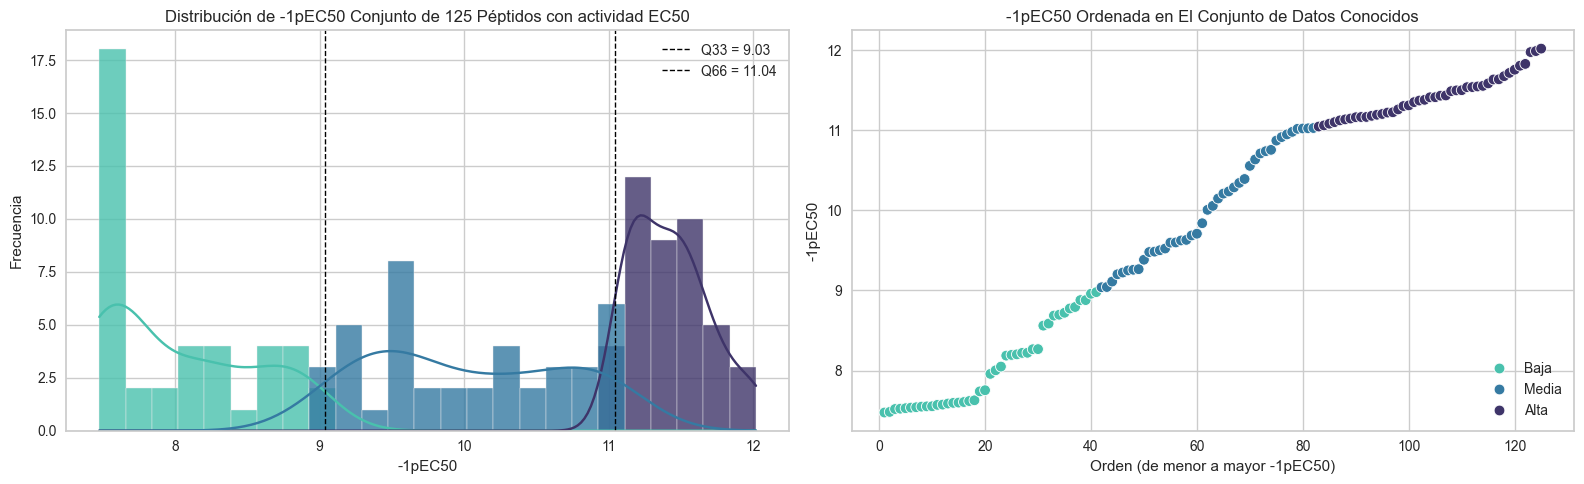


Resumen por categoría:
           n   promedio        min        max
Potencia                                     
Alta      43  11.421007  11.045275  12.017729
Baja      41   8.040037   7.476254   8.978810
Media     41  10.031697   9.039529  11.026872

Top 15 registros de categoría "Alta":


,ID,-1pEC50,Potencia
116,seq_pep117,12.017729,Alta
25,seq_pep26,11.987163,Alta
6,seq_pep7,11.974694,Alta
10,seq_pep11,11.826814,Alta
92,seq_pep93,11.804100,Alta
57,seq_pep58,11.754487,Alta
26,seq_pep27,11.714442,Alta
114,seq_pep115,11.673664,Alta
55,seq_pep56,11.634512,Alta
9,seq_pep10,11.632644,Alta


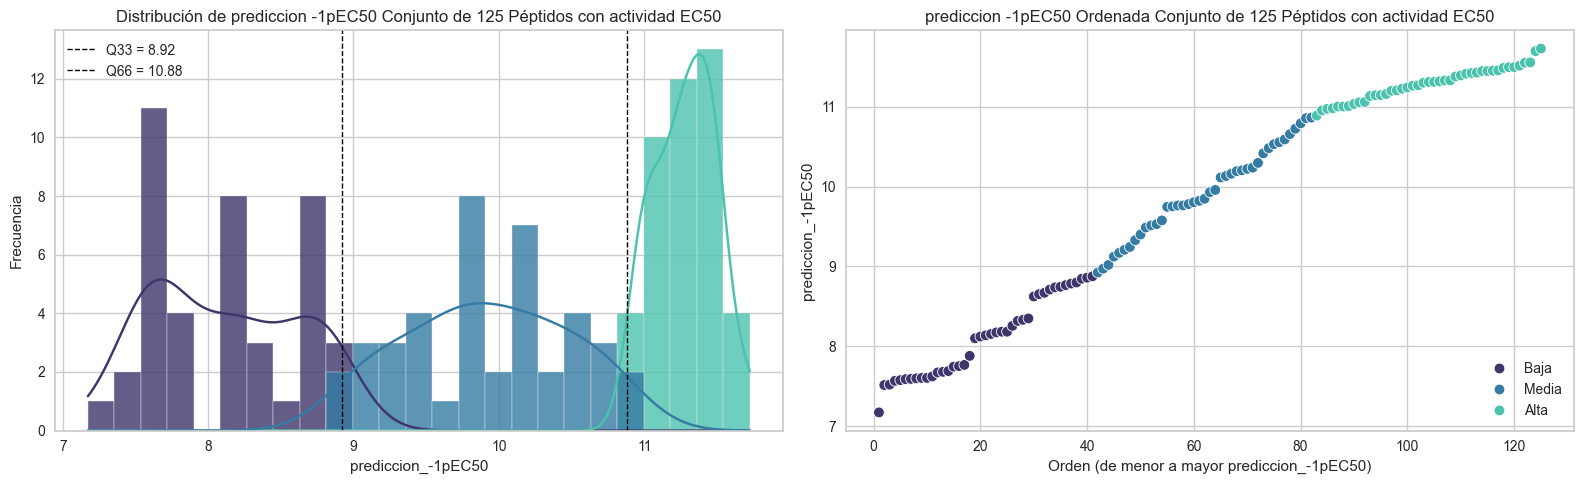


Resumen por categoría:
           n   promedio        min        max
Potencia                                     
Alta      43  11.282384  10.887796  11.726441
Baja      41   8.110562   7.172874   8.875807
Media     41   9.918632   8.923643  10.862871

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
6,seq_pep7,11.726441,Alta
25,seq_pep26,11.694712,Alta
26,seq_pep27,11.553534,Alta
92,seq_pep93,11.548939,Alta
9,seq_pep10,11.513391,Alta
63,seq_pep64,11.495036,Alta
84,seq_pep85,11.493444,Alta
78,seq_pep79,11.484716,Alta
80,seq_pep81,11.453832,Alta
83,seq_pep84,11.449980,Alta


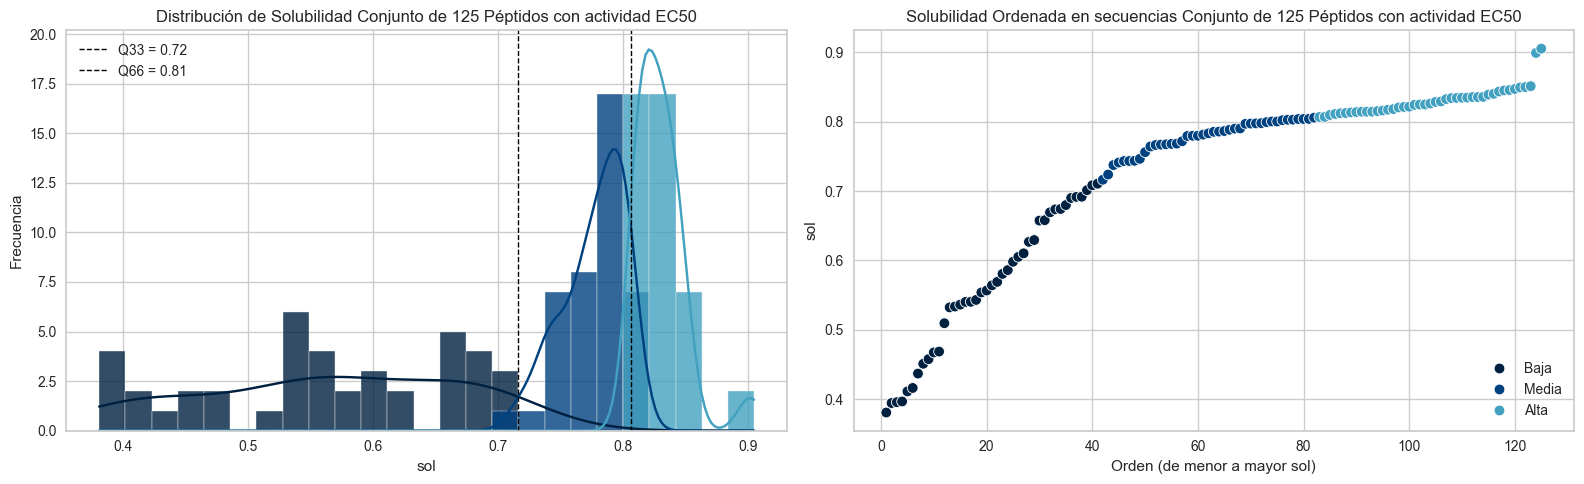


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      43  0.830344  0.806707  0.905196
Baja      41  0.563361  0.380827  0.710580
Media     41  0.777207  0.716259  0.805688

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
46,seq_pep47,0.905196,Alta
47,seq_pep48,0.898952,Alta
110,seq_pep111,0.851075,Alta
0,seq_pep1,0.849804,Alta
12,seq_pep13,0.849240,Alta
10,seq_pep11,0.847004,Alta
1,seq_pep2,0.845523,Alta
52,seq_pep53,0.844946,Alta
3,seq_pep4,0.843368,Alta
11,seq_pep12,0.840037,Alta


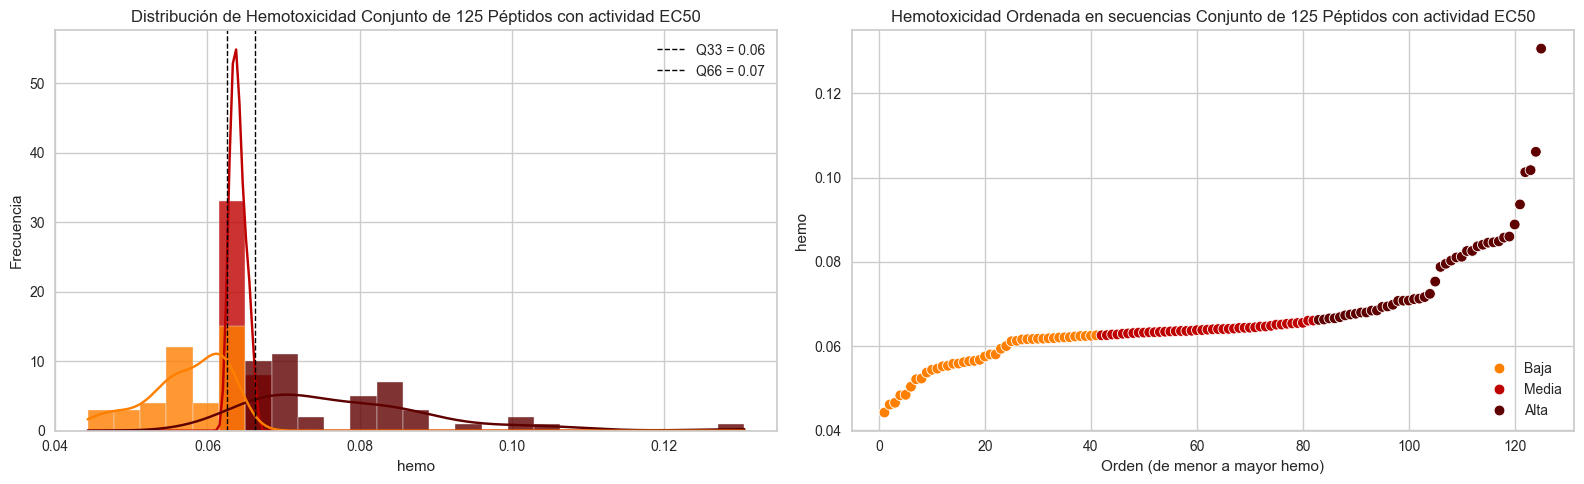


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      43  0.078426  0.066235  0.130579
Baja      41  0.057206  0.044251  0.062554
Media     41  0.064023  0.062560  0.066066

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
45,seq_pep46,0.130579,Alta
6,seq_pep7,0.106102,Alta
46,seq_pep47,0.101750,Alta
8,seq_pep9,0.101251,Alta
7,seq_pep8,0.093613,Alta
119,seq_pep120,0.088852,Alta
17,seq_pep18,0.085996,Alta
16,seq_pep17,0.085746,Alta
22,seq_pep23,0.084847,Alta
123,seq_pep124,0.084626,Alta


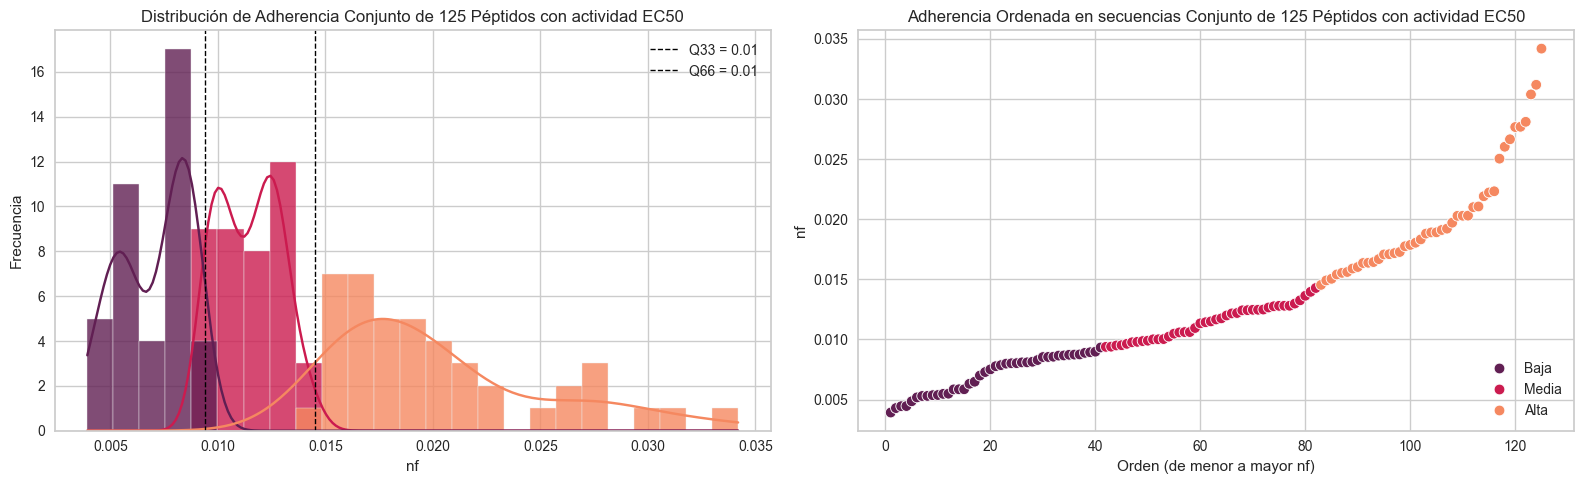


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      43  0.020245  0.014541  0.034196
Baja      41  0.007055  0.003922  0.009333
Media     41  0.011430  0.009386  0.014283

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
0,seq_pep1,0.034196,Alta
1,seq_pep2,0.031188,Alta
86,seq_pep87,0.030385,Alta
3,seq_pep4,0.028107,Alta
4,seq_pep5,0.027693,Alta
2,seq_pep3,0.027671,Alta
5,seq_pep6,0.026654,Alta
12,seq_pep13,0.026033,Alta
10,seq_pep11,0.025042,Alta
64,seq_pep65,0.022327,Alta


In [15]:
%matplotlib inline 
clasificar_y_graficar_cuantiles(
    df_input=df_125_conocidos,   columna_valor='-1pEC50', 
    columna_id='ID', top_n=15,palette='mako_r',
    titulo_distribucion='Distribución de -1pEC50 Conjunto de 125 Péptidos con actividad EC50',
    titulo_ordenado='-1pEC50 Ordenada en El Conjunto de Datos Conocidos')

clasificar_y_graficar_cuantiles(
    df_input=df_125_conocidos,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 Conjunto de 125 Péptidos con actividad EC50',
    titulo_ordenado='prediccion -1pEC50 Ordenada Conjunto de 125 Péptidos con actividad EC50')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_125_conocidos,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad Conjunto de 125 Péptidos con actividad EC50',
    titulo_ordenado='Solubilidad Ordenada en secuencias Conjunto de 125 Péptidos con actividad EC50'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_125_conocidos,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad Conjunto de 125 Péptidos con actividad EC50',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias Conjunto de 125 Péptidos con actividad EC50'
)

clasificar_y_graficar_cuantiles(
    df_input=df_125_conocidos,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia Conjunto de 125 Péptidos con actividad EC50',
    titulo_ordenado='Adherencia Ordenada en secuencias Conjunto de 125 Péptidos con actividad EC50'
)

### Graficos de las Propiedades predichas en el conjunto de de alta diversidad

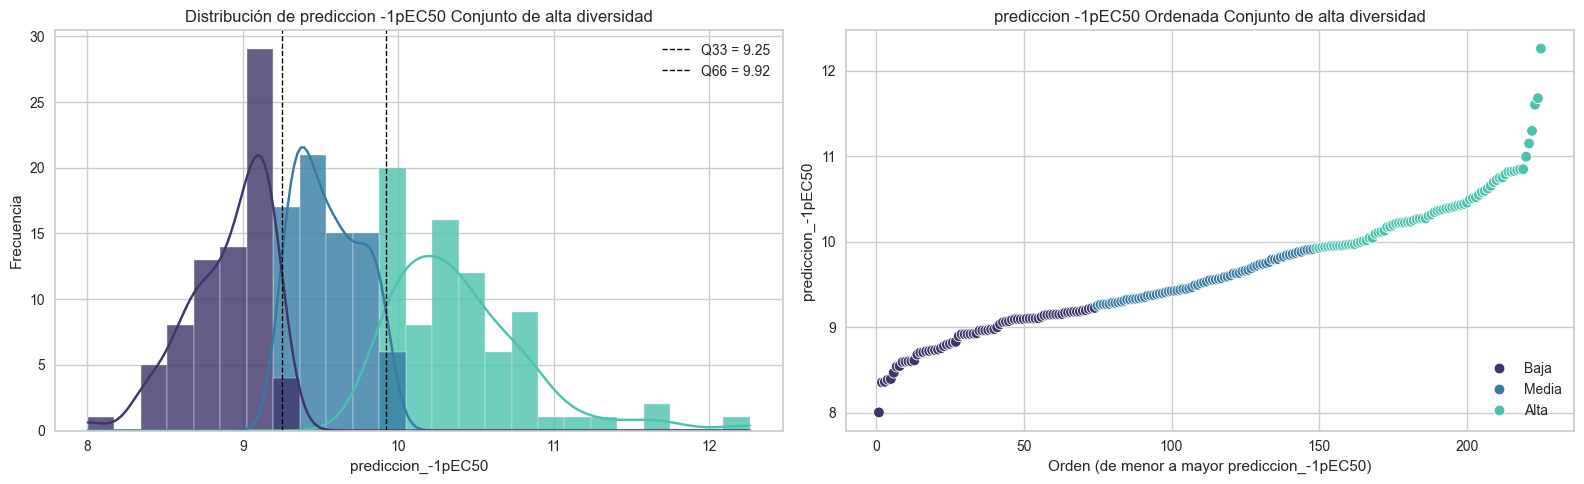


Resumen por categoría:
           n   promedio       min        max
Potencia                                    
Alta      77  10.400126  9.926014  12.261923
Baja      74   8.909281  8.003110   9.225581
Media     74   9.551358  9.251299   9.915365

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
83,AF-A0A437DK50-F1,12.261923,Alta
40,AF-A0A3B3B937-F1,11.681027,Alta
121,AF-A0A672I3H1-F1,11.605798,Alta
129,AF-A0A6I9NZD6-F1,11.298767,Alta
56,AF-A0A3B5K1X4-F1,11.150911,Alta
132,AF-A0A6J2R6I7-F1,10.996475,Alta
120,AF-A0A671YGN8-F1,10.849584,Alta
8,AF-A0A0F8AUA0-F1,10.848323,Alta
103,AF-A0A5J5CHC0-F1,10.838993,Alta
172,AF-G1Q6H7-F1,10.826580,Alta


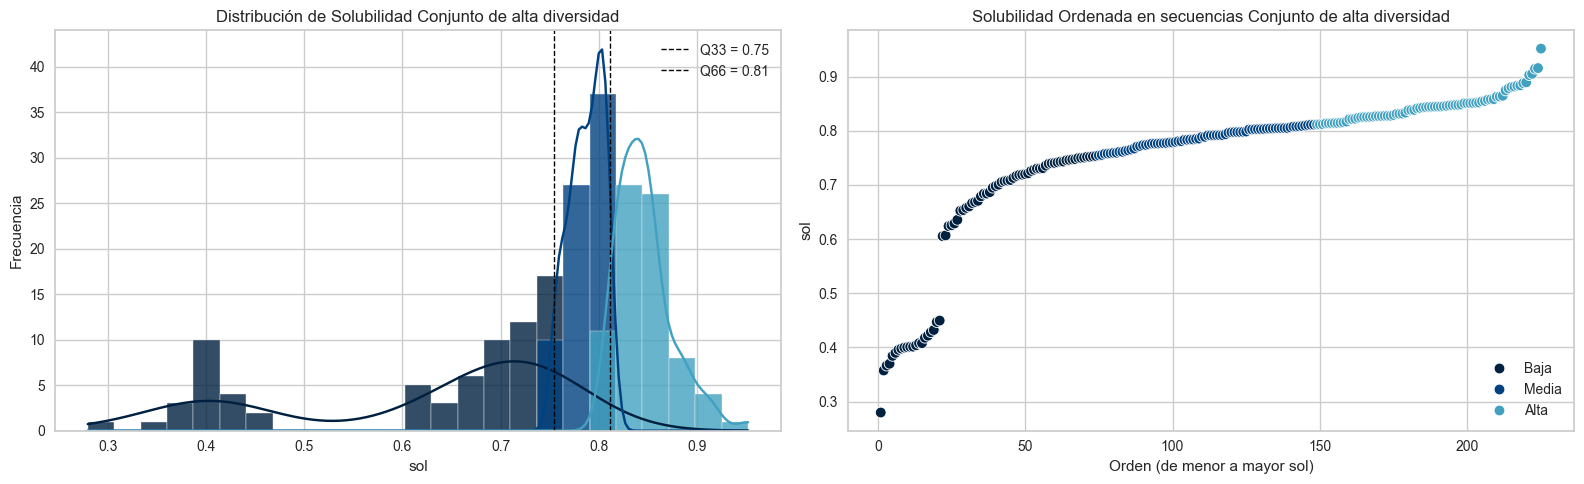


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      77  0.846210  0.811645  0.951705
Baja      74  0.618319  0.279729  0.753454
Media     74  0.787171  0.754591  0.811238

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
143,AF-A0A7J5Z6B7-F1,0.951705,Alta
204,AF-Q7LZN2-F1,0.915737,Alta
167,AF-C0HJJ5-F1,0.914667,Alta
165,AF-C0HJJ3-F1,0.905193,Alta
206,AF-Q7LZN4-F1,0.902802,Alta
168,AF-C0HJJ6-F1,0.889321,Alta
76,AF-A0A3Q3FFF5-F1,0.887957,Alta
214,Dulaglutide,0.883833,Alta
222,XP_029460758.1,0.883336,Alta
217,NP_001079142.1,0.881748,Alta


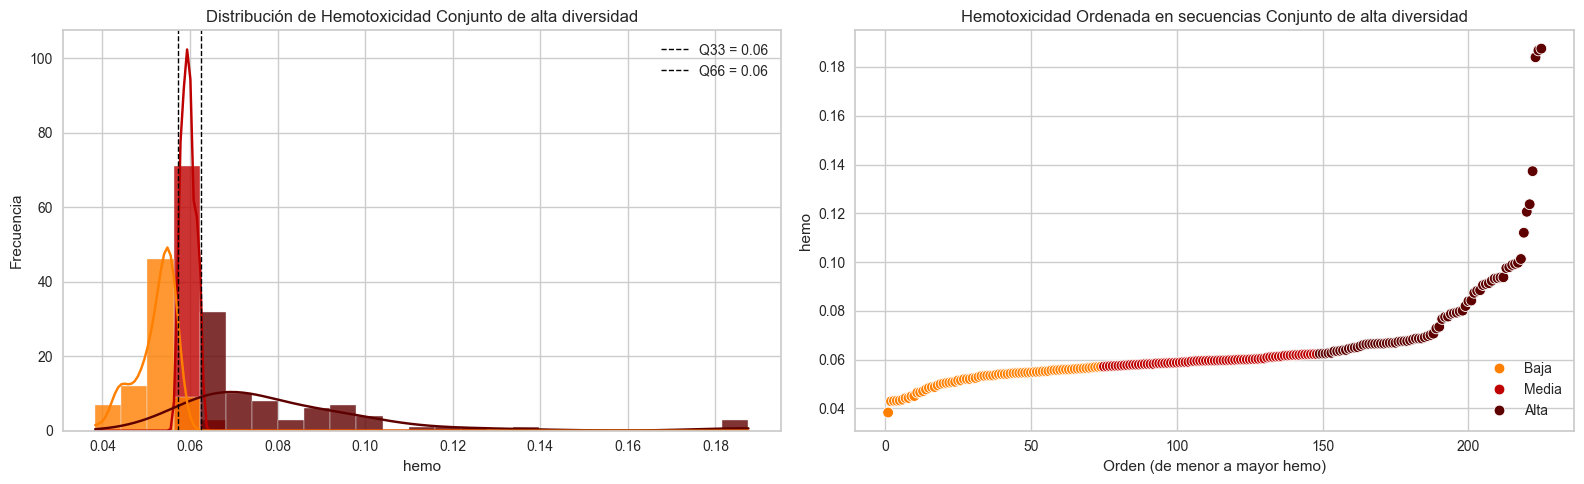


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      77  0.082112  0.062419  0.187523
Baja      74  0.052089  0.038335  0.057144
Media     74  0.059623  0.057190  0.062262

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
152,AF-A0A7L1V7B0-F1,0.187523,Alta
149,AF-A0A7K8VMT8-F1,0.186778,Alta
147,AF-A0A7K5DTR4-F1,0.183961,Alta
108,AF-A0A667XFV4-F1,0.137271,Alta
175,AF-G1QFC1-F1,0.123714,Alta
64,AF-A0A3Q0ST55-F1,0.120623,Alta
24,AF-A0A1S3NVN9-F1,0.112043,Alta
7,AF-A0A091P079-F1,0.101275,Alta
180,AF-H9GKR8-F1,0.099744,Alta
160,AF-A0A7L3GS93-F1,0.099264,Alta


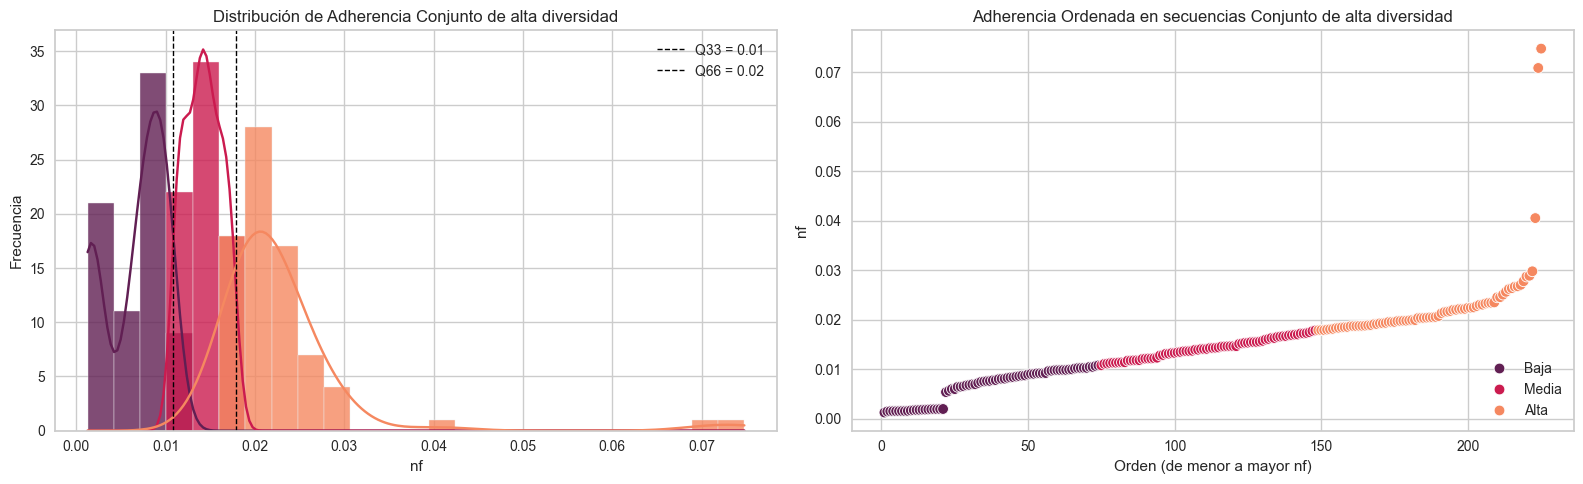


Resumen por categoría:
           n  promedio       min       max
Potencia                                  
Alta      77  0.022981  0.017887  0.074783
Baja      74  0.006612  0.001266  0.010794
Media     74  0.014216  0.010799  0.017850

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
123,AF-A0A672NPW9-F1,0.074783,Alta
135,AF-A0A6P6M3Y7-F1,0.070871,Alta
188,AF-P0C235-F1,0.040546,Alta
124,AF-A0A672Q9F1-F1,0.029796,Alta
118,AF-A0A671T9R4-F1,0.028904,Alta
23,AF-A0A1S3MVQ3-F1,0.028741,Alta
207,AF-Q9DDE6-F1,0.027780,Alta
86,AF-A0A498N7U8-F1,0.027058,Alta
91,AF-A0A4W4FPL9-F1,0.026756,Alta
199,AF-Q6RYB3-F1,0.026699,Alta


In [16]:
%matplotlib inline 

clasificar_y_graficar_cuantiles(
    df_input=df_glp1,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 Conjunto de alta diversidad',
    titulo_ordenado='prediccion -1pEC50 Ordenada Conjunto de alta diversidad')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_glp1,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad Conjunto de alta diversidad',
    titulo_ordenado='Solubilidad Ordenada en secuencias Conjunto de alta diversidad'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_glp1,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad Conjunto de alta diversidad',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias Conjunto de alta diversidad'
)

clasificar_y_graficar_cuantiles(
    df_input=df_glp1,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia Conjunto de alta diversidad',
    titulo_ordenado='Adherencia Ordenada en secuencias Conjunto de alta diversidad'
)


### Graficos de las Propiedades predichas en el conjunto de 

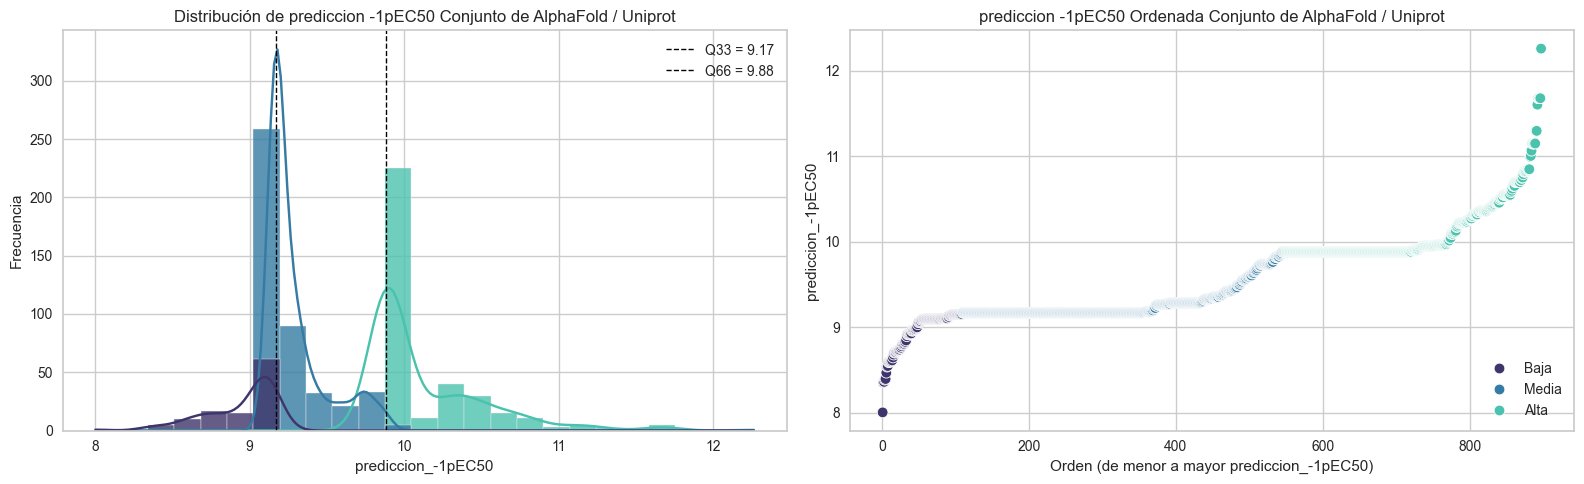


Resumen por categoría:
            n   promedio       min        max
Potencia                                     
Alta      348  10.133605  9.882810  12.261923
Baja      109   8.943057  8.003110   9.154276
Media     440   9.288798  9.170109   9.881364

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
232,AF-A0A437DK50-F1,12.261923,Alta
184,AF-A0A3P9LIZ7-F1,11.681027,Alta
657,AF-H2LC36-F1,11.681027,Alta
129,AF-A0A3B3B937-F1,11.681027,Alta
182,AF-A0A3P9IFL7-F1,11.681027,Alta
301,AF-A0A672I3H1-F1,11.605798,Alta
388,AF-A0A6P8U7R0-F1,11.298767,Alta
345,AF-A0A6I9NZD6-F1,11.298767,Alta
158,AF-A0A3B5K1X4-F1,11.150911,Alta
662,AF-H3D6X5-F1,11.150911,Alta


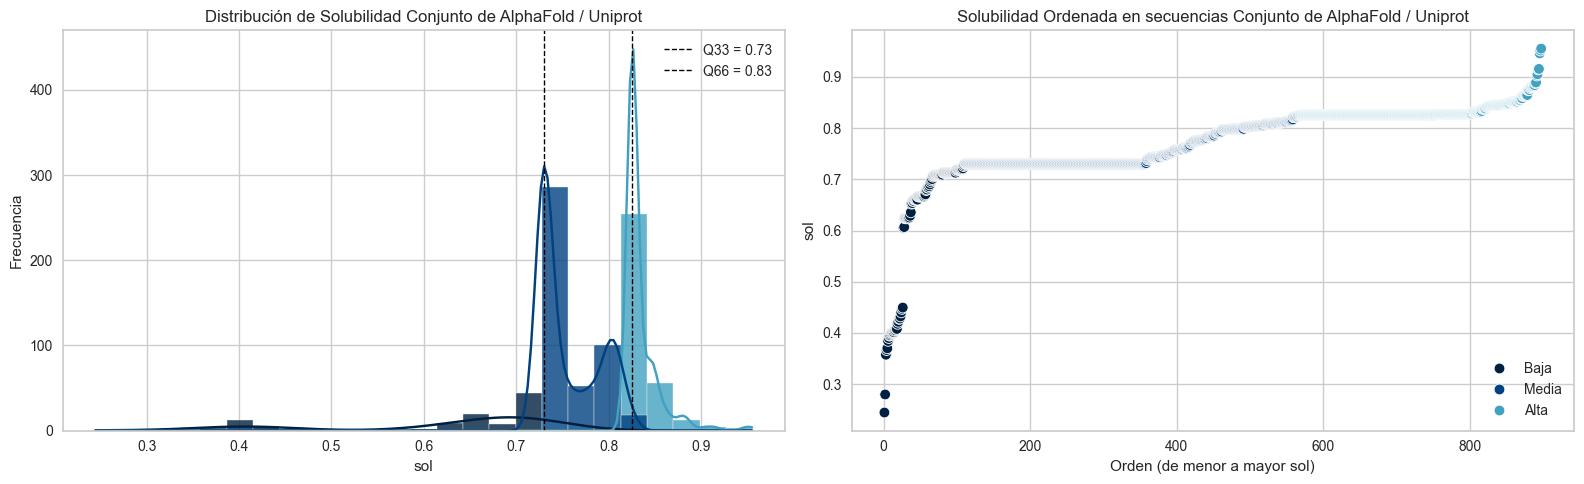


Resumen por categoría:
            n  promedio       min       max
Potencia                                   
Alta      329  0.834488  0.825296  0.955395
Baja      110  0.617864  0.244463  0.728038
Media     458  0.755570  0.730178  0.824885

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
704,AF-Q6IUP8-F1,0.955395,Alta
394,AF-A0A7J5Z6B7-F1,0.951705,Alta
312,AF-A0A673HLN7-F1,0.946053,Alta
720,AF-Q7LZN2-F1,0.915737,Alta
630,AF-C0HJJ5-F1,0.914667,Alta
628,AF-C0HJJ3-F1,0.905193,Alta
722,AF-Q7LZN4-F1,0.902802,Alta
631,AF-C0HJJ6-F1,0.889321,Alta
219,AF-A0A3Q3FFF5-F1,0.887957,Alta
745,Dulaglutide,0.883833,Alta


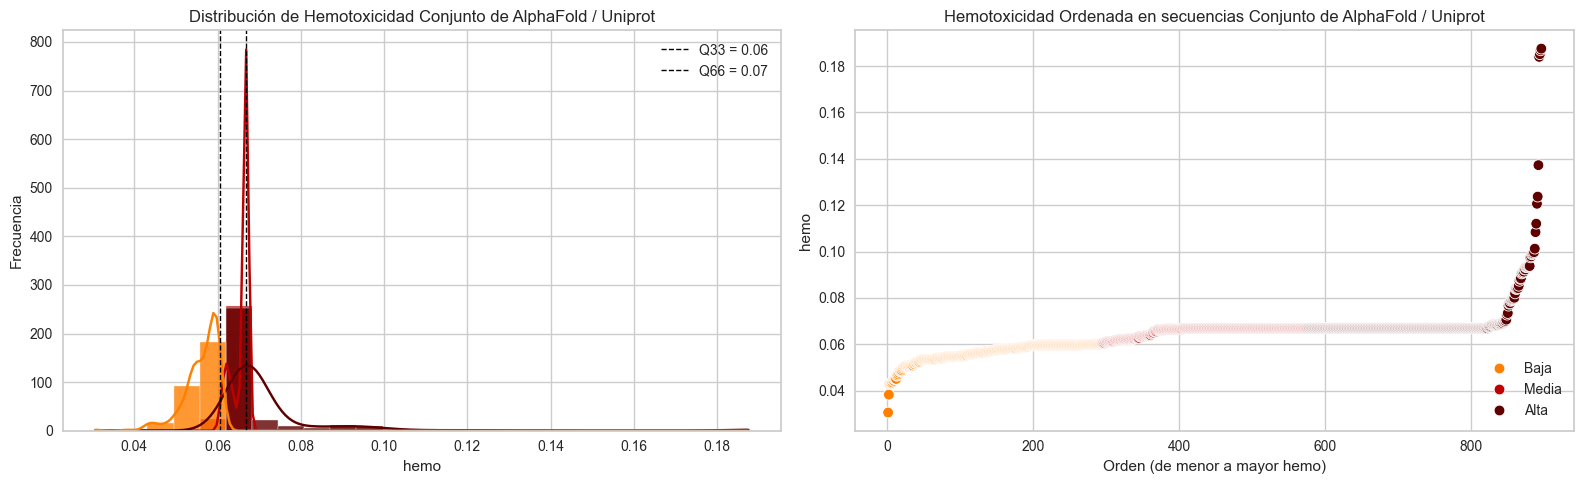


Resumen por categoría:
            n  promedio       min       max
Potencia                                   
Alta      321  0.071912  0.066916  0.187523
Baja      295  0.056162  0.030618  0.060451
Media     281  0.065712  0.060497  0.066893

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
537,AF-A0A7L1V7B0-F1,0.187523,Alta
485,AF-A0A7K8VMT8-F1,0.186778,Alta
313,AF-A0A673HMH6-F1,0.185114,Alta
417,AF-A0A7K5DTR4-F1,0.183961,Alta
279,AF-A0A667XFV4-F1,0.137271,Alta
644,AF-G1QFC1-F1,0.123714,Alta
188,AF-A0A3Q0ST55-F1,0.120623,Alta
58,AF-A0A1S3NVN9-F1,0.112043,Alta
704,AF-Q6IUP8-F1,0.108387,Alta
13,AF-A0A091P079-F1,0.101275,Alta


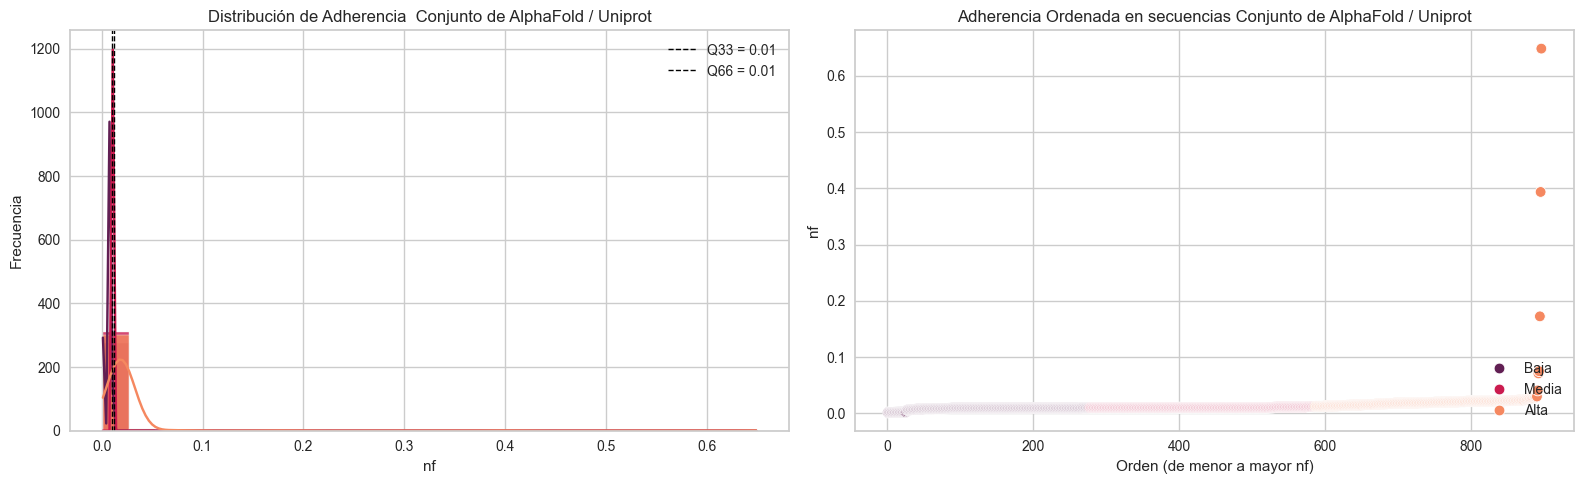


Resumen por categoría:
            n  promedio       min       max
Potencia                                   
Alta      311  0.022861  0.012247  0.648717
Baja      277  0.008192  0.001266  0.009868
Media     309  0.010213  0.009954  0.012194

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
312,AF-A0A673HLN7-F1,0.648717,Alta
587,AF-A0A7S9CE09-F1,0.393677,Alta
313,AF-A0A673HMH6-F1,0.172374,Alta
304,AF-A0A672NPW9-F1,0.074783,Alta
374,AF-A0A6P6M3Y7-F1,0.070871,Alta
684,AF-P0C235-F1,0.040546,Alta
306,AF-A0A672Q9F1-F1,0.029796,Alta
297,AF-A0A671T9R4-F1,0.028904,Alta
725,AF-Q91189-F1,0.028741,Alta
57,AF-A0A1S3MVQ3-F1,0.028741,Alta


In [17]:
    
%matplotlib inline 

clasificar_y_graficar_cuantiles(
    df_input=df_glucagon_like_peptides,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 Conjunto de AlphaFold / Uniprot',
    titulo_ordenado='prediccion -1pEC50 Ordenada Conjunto de AlphaFold / Uniprot')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_glucagon_like_peptides,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad Conjunto de AlphaFold / Uniprot',
    titulo_ordenado='Solubilidad Ordenada en secuencias Conjunto de AlphaFold / Uniprot'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_glucagon_like_peptides,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad Conjunto de AlphaFold / Uniprot',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias Conjunto de AlphaFold / Uniprot'
)

clasificar_y_graficar_cuantiles(
    df_input=df_glucagon_like_peptides,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia  Conjunto de AlphaFold / Uniprot',
    titulo_ordenado='Adherencia Ordenada en secuencias Conjunto de AlphaFold / Uniprot'
)

# Calculo de pEC50 sobre los datos de AlphaFold / Uniprot usados para entrenar los modelos generativos


### Como linea extra de investigación buscamos las especies de los péptidos con mayor actividad biológica a partir de los datos obtenidos de alpha fold

Destacan como resultados de interes las siguientes especies:

[Salarias fasciatus](https://es.wikipedia.org/wiki/Salarias_fasciatus)


[Oryzias javanicus](https://es.wikipedia.org/wiki/Oryzias_javanicus)


[Liraglutida, compuesto sintético](https://es.wikipedia.org/wiki/Liraglutida)


[Saccharomyces cerevisiae](https://es.wikipedia.org/wiki/Saccharomyces_cerevisiae)


[Emberiza bruniceps](https://es.wikipedia.org/wiki/Emberiza_bruniceps)


[Sinocyclocheilus rhinocerous](https://es.wikipedia.org/wiki/Sinocyclocheilus_rhinocerous)


[David's myotis](https://en.wikipedia.org/wiki/David%27s_myotis)


[Cottoperca gobio](https://en.wikipedia.org/wiki/Cottoperca_gobio)


[Oryzias latipes](https://es.wikipedia.org/wiki/Oryzias_latipes)


[Myotis lucifugus](https://es.wikipedia.org/wiki/Myotis_lucifugus)

Estas especies tiene un GLP-1 con mayor actividad biológica en comparación con el GLP-1 humano, de acuerdo con el modelo predictivo, lo cual es interesante para futuras investigaciones en el diseño de péptidos agonistas del receptor GLP-1.

In [18]:
# Union de los conjuntos de datos previo a la generación de nuevas secuencias

#unir todos los peptidos evaluados en un solo dataframe
df_todos_peptidos = pd.concat([df_pro_glucagon_humano, df_glucagon_like_peptides,df_125_conocidos, df_glp1, ], ignore_index=True)
# Eliminación de duplicados por secuencia
#df_todos_peptidos = df_todos_peptidos.drop_duplicates(subset=['sequence'])
df_todos_peptidos.shape

(1248, 1302)

In [19]:
# buscar los compuestos con mayor actividad de los que se conoce la especie

df_mejores_especies = df_todos_peptidos[df_todos_peptidos['Species'].notnull()].sort_values(by='prediccion_-1pEC50', ascending=False)
df_mejores_especies[['ID', 'Description', 'Species','organismCommonNames', 'prediccion_-1pEC50', 'sol', 'hemo', 'nf']].head(30)

,ID,Description,Species,organismCommonNames,prediccion_-1pEC50,sol,hemo,nf
233,AF-A0A437DK50-F1,Uncharacterized protein,Oryzias javanicus,NaN,12.261923,0.811936,0.057697,0.011326
130,AF-A0A3B3B937-F1,Glucagon-1,Oryzias melastigma,Marine medaka,11.681027,0.831699,0.057883,0.013283
658,AF-H2LC36-F1,Uncharacterized protein,Oryzias latipes,NaN,11.681027,0.831699,0.057883,0.013283
183,AF-A0A3P9IFL7-F1,Glucagon,Oryzias latipes,Japanese rice fish,11.681027,0.831699,0.057883,0.013283
185,AF-A0A3P9LIZ7-F1,Glucagon a,Oryzias latipes,Japanese rice fish,11.681027,0.831699,0.057883,0.013283
302,AF-A0A672I3H1-F1,Glucagon a,Salarias fasciatus,Jewelled blenny,11.605798,0.791959,0.056356,0.016683
346,AF-A0A6I9NZD6-F1,glucagon-1-like,Notothenia coriiceps (black rockcod),NaN,11.298767,0.750005,0.066930,0.011758
389,AF-A0A6P8U7R0-F1,glucagon-1-like,Gymnodraco acuticeps,NaN,11.298767,0.750005,0.066930,0.011758
660,AF-H2TB61-F1,Uncharacterized protein,Takifugu rubripes,NaN,11.150911,0.757520,0.059583,0.014594
159,AF-A0A3B5K1X4-F1,Uncharacterized protein,Takifugu rubripes,NaN,11.150911,0.757520,0.059583,0.014594


In [20]:
## Resultados de la predicción de actividad biológica del pro-glucagon Humano como referencia
df_pro_glucagon_humano[['ID', 'Description', 'Species','organismCommonNames', 'prediccion_-1pEC50', 'sol', 'hemo', 'nf']]

,ID,Description,Species,organismCommonNames,prediccion_-1pEC50,sol,hemo,nf
875,sp-P01275-GLUC_HUMAN,Glucagon,Pan troglodytes,Chimpanzee,9.88281,0.825296,0.066893,0.009175


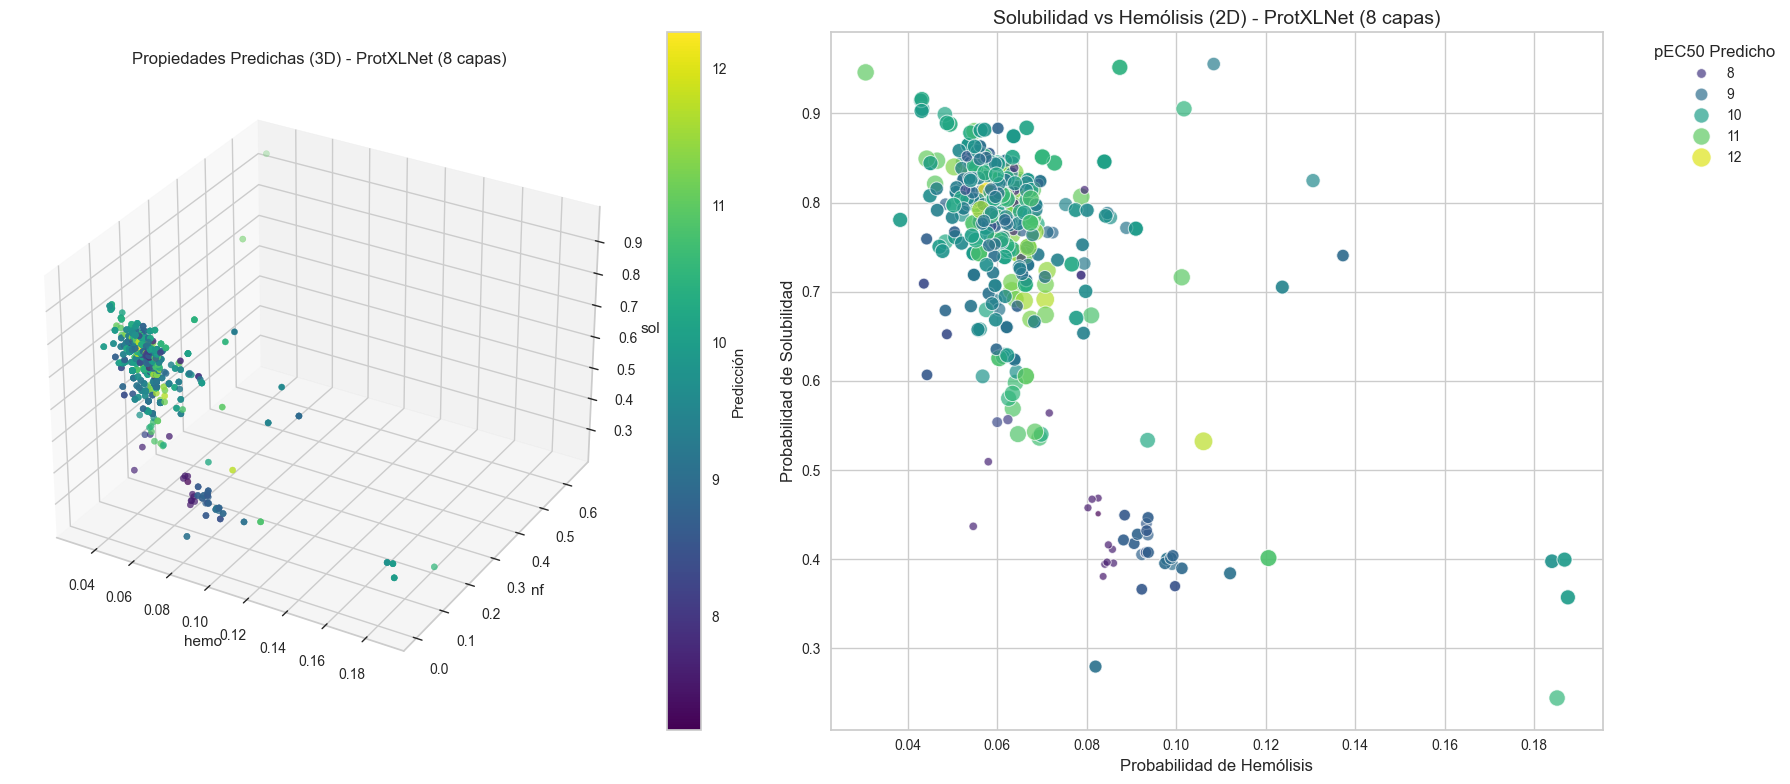

In [21]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Crear figura con 2 subplots (1 fila, 2 columnas)
fig = plt.figure(figsize=(18, 8))

# === Subplot 1: PCA 3D ===
ax1 = fig.add_subplot(121, projection='3d')

plot_pca_3d(
    df_todos_peptidos,
    pc_x='hemo',
    pc_y='nf',
    pc_z='sol',
    color_by='prediccion_-1pEC50',
    label='Predicción',
    ax=ax1,
    cmap='viridis',
    title='Propiedades Predichas (3D) - ProtXLNet (8 capas)',
    figsize=(8, 5),  # Este parámetro se ignora al usar un ax externo
)

# === Subplot 2: Scatter 2D ===
ax2 = fig.add_subplot(122)

scatter = sns.scatterplot(
    data=df_todos_peptidos,
    x='hemo',
    y='sol',
    hue='prediccion_-1pEC50',
    palette='viridis',
    size='prediccion_-1pEC50',
    sizes=(20, 200),
    alpha=0.7,
    edgecolor='w',
    ax=ax2
)

ax2.set_title('Solubilidad vs Hemólisis (2D) - ProtXLNet (8 capas)', fontsize=14)
ax2.set_xlabel('Probabilidad de Hemólisis', fontsize=12)
ax2.set_ylabel('Probabilidad de Solubilidad', fontsize=12)
ax2.grid(True)
ax2.legend(title='pEC50 Predicho', bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajustar espacios
plt.tight_layout()
plt.show()


-------

## Generación de nuevas secuencias usando modelos de lenguaje
Para la generación de nuevas secuencias peptídicas con potencial actividad agonista del receptor GLP-1, se emplean los modelos generativos de lenguaje ProxLNet y ProtGPT2. Estos modelos, basados en arquitecturas Transformer, han sido entrenados previamente con grandes conjuntos de datos de secuencias proteicas, lo que les permite capturar patrones complejos y generar nuevas secuencias coherentes y biológicamente plausibles.
Para esta atividad se entrenaron con el conjunto de datos de alta diversidad obtenidos de CD-Hit para facilitar la generación de secuencias con mayor similitud al GLP-1.

Como primer paso, se seleccionan las secuencias con mejores características de todo el conjunto para usarlas como prompt de inicio para la generación de nuevas secuencias.


In [22]:
# carga de Modelos de Machine Learning y Transformers
from sklearn.model_selection import train_test_split
from transformers import (
    XLNetLMHeadModel,
    XLNetTokenizer,
    Trainer,
    TrainingArguments,
    DataCollatorForLanguageModeling
)
from datasets import Dataset

from src.ProtXLNet_generator import generate_with_protxlnet_pipeline
from src.ProtGPT2_generator import generate_with_protgpt2_pipeline

import random
random.seed(132400)

In [23]:
# Selección de los mejores péptidos como prompts

df_seleccionadas = df_todos_peptidos.drop_duplicates('sequence').sort_values(by=['prediccion_-1pEC50','sol','hemo','nf'], ascending=[False, False, True, True])
# Filtrar predicciones con pEC50 > 10.6 y longitud <= 60
df_seleccionadas = df_seleccionadas[
    (df_seleccionadas['prediccion_-1pEC50'] > 10.6) & 
    (df_seleccionadas['sequence'].str.len() <= 60)]

df_seleccionadas.info()
display(df_seleccionadas[["ID","sequence","prediccion_-1pEC50","sol","hemo","nf","Species","organismCommonNames"]])

<class 'pandas.core.frame.DataFrame'>
Index: 68 entries, 233 to 219
Columns: 1302 entries, ID to -1pEC50
dtypes: category(3), float32(1293), float64(4), object(2)
memory usage: 383.4+ KB


,ID,sequence,prediccion_-1pEC50,sol,hemo,nf,Species,organismCommonNames
233,AF-A0A437DK50-F1,HADGTFTSDVSAYLKEQAIKDFVAKLKAGQ,12.261923,0.811936,0.057697,0.011326,Oryzias javanicus,NaN
904,seq_pep7,YSQGTFTSDYSKYLEEEAVRLFIEWLLAG,11.726441,0.532305,0.106102,0.004857,NaN,NaN
923,seq_pep26,YSEGTFTSDYSKLLEEEAVRDFIEWLLAGGPSSGAPPPS,11.694712,0.691562,0.070741,0.011432,NaN,NaN
130,AF-A0A3B3B937-F1,HADGTFTSDVSAYLKEQAIKDFVAKLKSGQ,11.681027,0.831699,0.057883,0.013283,Oryzias melastigma,Marine medaka
302,AF-A0A672I3H1-F1,HTDGTFTSDVSAYLNDRAVKEFVARLKSGQ,11.605798,0.791959,0.056356,0.016683,Salarias fasciatus,Jewelled blenny
...,...,...,...,...,...,...,...,...
204,AF-A0A3Q2E1H1-F1,HADGTFTSDVSSYLKDQAIKDFVAKLKSGE,10.722605,0.847625,0.057955,0.017008,Cyprinodon variegatus,NaN
150,AF-A0A3B4TZN0-F1,HADGTFTSDVSSYLKDQAIKDFVAKLKSGQ,10.698114,0.831273,0.058237,0.017850,Seriola dumerili,NaN
932,seq_pep35,YAEGTFTSDYSIYLDEQAAQEFVNWLLAGGPSSGAPPPS,10.656429,0.598091,0.064100,0.012660,NaN,NaN
145,AF-A0A3B4AQY3-F1,HADGTFTSDVSSYLKDQAIKDFVARLKSGQ,10.655051,0.783217,0.060055,0.017331,Periophthalmus magnuspinnatus,NaN


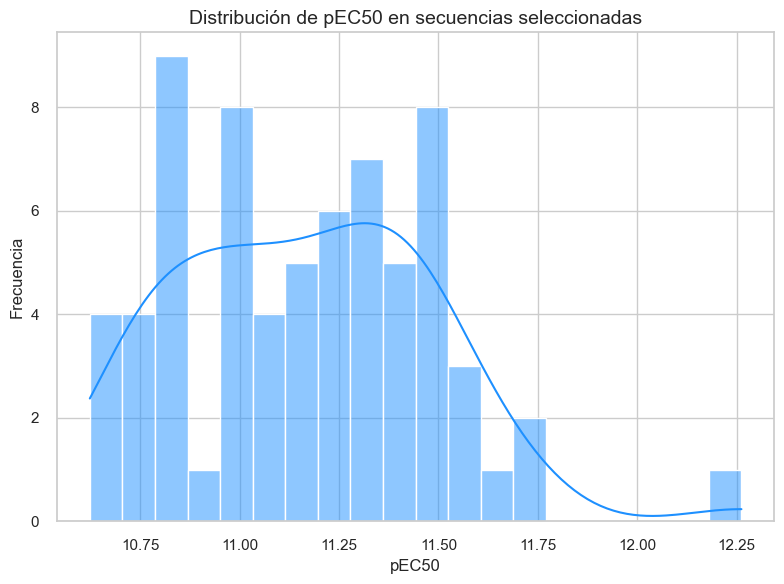

In [24]:
# Comparación de la distribución de pEC50 de las secuencias seleccionadas como semilla
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración del estilo de la visualización
sns.set(style="whitegrid")

plt.figure(figsize=(8, 6))
sns.histplot(df_seleccionadas['prediccion_-1pEC50'], kde=True, bins=20, color='dodgerblue')
plt.title('Distribución de pEC50 en secuencias seleccionadas', fontsize=14)
plt.xlabel('pEC50', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# Preparación de los prompts para la generación de nuevas secuencias para los modelos
prompt_sequences= df_seleccionadas['sequence'].tolist()
longitud_maxima = df_seleccionadas['sequence'].str.len().max()
longitud_minima = df_seleccionadas['sequence'].str.len().min()
sequences_base = df_seleccionadas['sequence'].tolist()
print(f"Longitud máxima de secuencia: {longitud_maxima}")
print(f"Longitud mínima de secuencia: {longitud_minima}")

Longitud máxima de secuencia: 41
Longitud mínima de secuencia: 4


### Generación de secuencias usando ProtGPT2

#### ProtGPT2

ProtGPT2 es un modelo de lenguaje especializado en el espacio proteico, diseñado para la generación de novo de secuencias peptídicas y proteínas. Las secuencias que produce conservan propiedades esenciales de las proteínas naturales, como propensión de aminoácidos, estructura secundaria y globularidad, mientras exploran regiones inéditas del espacio de diseño.

Basado en la arquitectura Transformer tipo GPT-2, ProtGPT2 cuenta con 36 capas, una dimensionalidad de 1280 y aproximadamente 738 millones de parámetros. Fue preentrenado en modo decodificador sobre la base UniRef50 (versión 2021_04), utilizando secuencias sin anotaciones bajo un enfoque auto-supervisado mediante un objetivo causal de predicción del siguiente token. Esto le permite aprender representaciones internas del “lenguaje” de las proteínas y generar secuencias coherentes y biológicamente plausibles.

En esta actividad se entreno el modelo usando el conjuntos de datos de alta diversidad de 225 Peptidos usando el script de entrenamiento proporcionado por los desarrolladores de ProtGPT2, ajustando hiperparámetros como la tasa de aprendizaje, el tamaño del lote y el número de épocas para optimizar la generación de secuencias con características deseables.

In [26]:
# Generar un timestamp para nombrar archivos a final de evitar sobreescrituras de resultados
from datetime import datetime
# Generar timestamp en formato AñoMesDía_HoraMinutoSegundo
File_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

In [27]:
# Generación de nuevas secuencias usando ProtGPT2
variants = generate_with_protgpt2_pipeline(
    prompt_sequences=prompt_sequences,
    num_variants_per_seq=20,
    num_return_sequences=5,
    max_length=longitud_maxima,
    min_length=longitud_minima,
    top_k=50,
    repetition_penalty=1.0,
)
df_secuencias_protGPT2 = pd.DataFrame(variants, columns=["sequence"])
df_secuencias_protGPT2['ID'] = [f"secuencia_{idx}" for idx in range(1, len(df_secuencias_protGPT2) + 1)]
df_secuencias_protGPT2 = df_secuencias_protGPT2[['ID', 'sequence']]
df_secuencias_protGPT2.head(10)

Usando dispositivo: cuda
Cargando pipeline de generación...


Loading weights:   0%|          | 0/437 [00:00<?, ?it/s]

Pipeline cargado.
Preparando las secuencias iniciales...


  0%|          | 0/68 [00:00<?, ?it/s]

Generando 1349 variantes (el pipeline manejará los lotes)...
Procesando salidas...


Procesando:   0%|          | 0/1349 [00:00<?, ?it/s]


Generación completada. Se obtuvieron 6055 variantes únicas.


,ID,sequence
0,secuencia_1,YSEGTFTSDYSKLKEEEANRLFIEWLLAGGPSSGCPPPSRP
1,secuencia_2,YAEGTFTSDYSIYLDEMAAQEFVNWLLAGGPSSGAPPPSTW
2,secuencia_3,HSEGTFTSDFASYLDYKATKEFIAQLTKGLTYVHNNNIAHR
3,secuencia_4,HSQGTFTSDYSKYLDSERARDFVQWCISEGPSSGAPPPSPP
4,secuencia_5,HSQGTFTSDYSKYLDERAAAKFVQWLLNGGPSSGAPPEGGA
5,secuencia_6,HGEGTFTSDVSSYMEFQLVDEFIAWLLKGRAPPTSPIAWPL
6,secuencia_7,HSGGTFTSDYSKYLESERARDFVQWLVAGGSEVRMDTYFG
7,secuencia_8,YSEGTFTSDYSKLLERQAIDEFVNKLLKGGPSSGAPPPSAS
8,secuencia_9,HAEGTHTSDVSSYLEGQAAKEFIAWLVGRCRAQDTREFPRW
9,secuencia_10,QSEGTFTSSGKTMTAYTYKYDSNGNLIEATANG


#### Cálculo de las características necesarias para la predicción de la actividad biológica

In [28]:
# Cálculo de descriptores y actividad biológica predicha para las nuevas secuencias generadas con ProtGPT2

df_secuencias_protGPT2 = calcular_descriptores_ifeature(
        directorio_temporal=directorio_temporal,
        dataframe=df_secuencias_protGPT2,
        sequence_col='sequence',
        id_col='ID',
        descriptores=descriptores,
        ifeatures_settings_json=ifeatures_settings_json
    )
    
# Calculo de pEC50 sobre los datos de alpha fold y uniprot
df_secuencias_protGPT2 = predict_model(modelo_pycaret, data=df_secuencias_protGPT2)
df_secuencias_protGPT2.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para el conjunto obtenido de la base de datos de Aphafold
df_secuencias_protGPT2 = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_secuencias_protGPT2, 
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)
 

Success! DataFrame has been saved to 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132158.fasta'.
Inspecting file: d:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132158.fasta...
  - OK! File is structurally valid. Found 6055 records.
'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132158.fasta' es válido. Se encontraron 6055 registros.
Iniciando cálculo de 14 descriptores...


calculando descriptores:   0%|          | 0/14 [00:00<?, ?it/s]

File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
Cálculo de descriptores finalizado.
Descriptores unidos al DataFrame. Forma final: (6055, 1292)
Archivo temporal 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132158.fasta' eliminado.
Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


...

Procesando caracteristica: sol


  0%|          | 0/6055 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/6055 [00:00<?, ?it/s]

In [29]:
# guardar en un archivo CSV las nuevas secuencias generadas
nombre_archivo = f"secuencias_nuevas_prot_gpt2_{File_timestamp}"
nombre_archivo_csv = f"{nombre_archivo}.csv"
nombre_archivo


'secuencias_nuevas_prot_gpt2_20260316_132121'

In [30]:
# Guardar el DataFrame en CSV
ruta_salida_secuencias_nuevas = Path(directorio_nuevas_secuencias /nombre_archivo_csv)

df_secuencias_protGPT2.to_csv(ruta_salida_secuencias_nuevas, index=False)
print(f"Archivo guardado: {ruta_salida_secuencias_nuevas}")

Archivo guardado: d:\source\Proyecto Integrador\glp-1_drug_discovery\data\processed\Actividad_5\secuencias_nuevas\secuencias_nuevas_prot_gpt2_20260316_132121.csv


### Resultados de la generación de nuevas secuencias con ProtGPT2

Las secuencias de ProtGPT2 tienen diversidad de aminoacidos y propiedades fisicoquímicas adecuadas para su evaluación como posibles agonistas del receptor GLP-1.

In [31]:
#Top  de secuencias generadas por propiedades deseadas 
df_secuencias_protGPT2.sort_values(by=['prediccion_-1pEC50','sol','hemo','nf'], ascending=[False, False, True, True], inplace=True)
df_secuencias_protGPT2[["ID","sequence","sol","hemo", "nf","prediccion_-1pEC50"]].head()


,ID,sequence,sol,hemo,nf,prediccion_-1pEC50
1791,secuencia_1792,HADGTFTSDVSAYLKEVAIKDFVAKLKAGQ,0.811455,0.060964,0.008280,12.510620
661,secuencia_662,HSQGTFTSDYSRYLDSRAAACFVQWAVSAGIWAGVAIGGIA,0.508010,0.069313,0.003977,12.462453
2573,secuencia_2574,HSQGTFTSDYSKYLESERARDFVQWLSAGGKKIWVCGGEVY,0.849535,0.055376,0.005630,12.418350
3794,secuencia_3795,HADGTFTSDVYAYLKEQAIKDFVAKLKAGQ,0.797162,0.056369,0.009164,12.354114
1256,secuencia_1257,HADGTFTSDVSAYLKEWAIKDFVAKLKAGQ,0.811043,0.060844,0.007428,12.353142


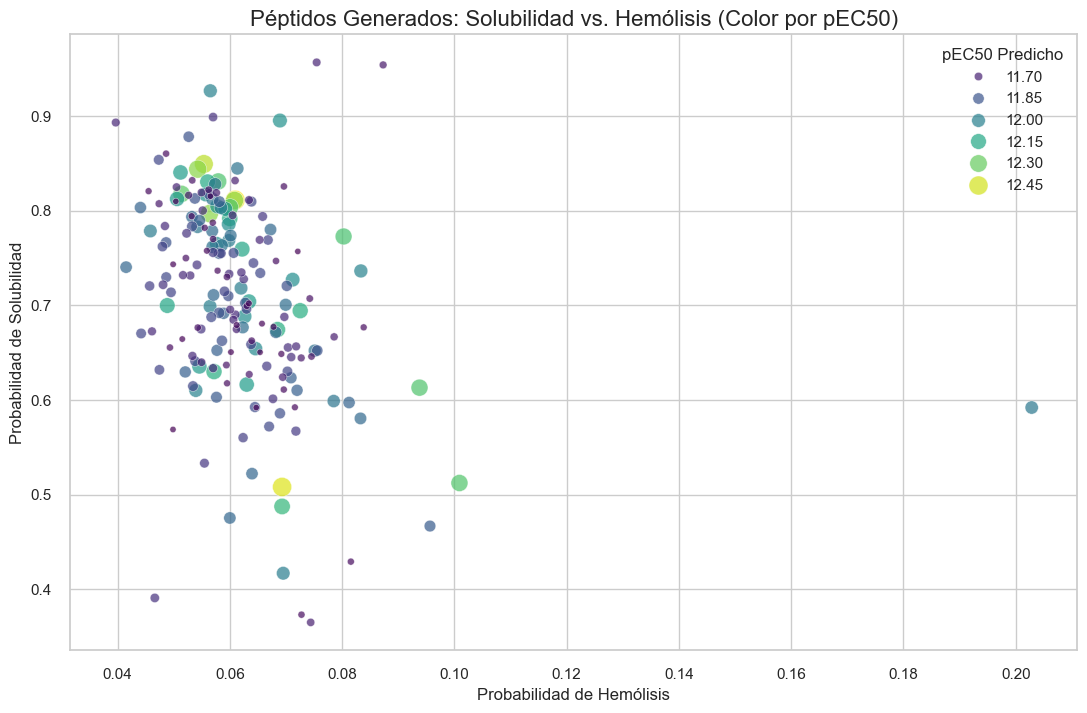

In [32]:
## Visualización de las propiedades predichas: Hemólisis vs Solubilidad coloreado por pEC50

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Crear el gráfico de dispersión
plt.figure(figsize=(13, 8))
scatter = sns.scatterplot(
    data=df_secuencias_protGPT2.head(200), # Mostrar solo las 200 secuencias con mayor pEC50
    x='hemo',
    y='sol',
    hue='prediccion_-1pEC50',
    palette='viridis', # Usamos un mapa de color "viridis" donde los colores más claros indican valores más altos
    size='prediccion_-1pEC50', # El tamaño del punto también representará el pEC50
    sizes=(20, 200),
    alpha=0.7,
    edgecolor='w'
)

# Añadir títulos y etiquetas
plt.title('Péptidos Generados: Solubilidad vs. Hemólisis (Color por pEC50)', fontsize=16)
plt.xlabel('Probabilidad de Hemólisis', fontsize=12)
plt.ylabel('Probabilidad de Solubilidad', fontsize=12)
plt.legend(title='pEC50 Predicho')
plt.grid(True)

# Mostrar el gráfico
plt.show()

#### Gráficos de las propiedades obtenias con ProtGPT2


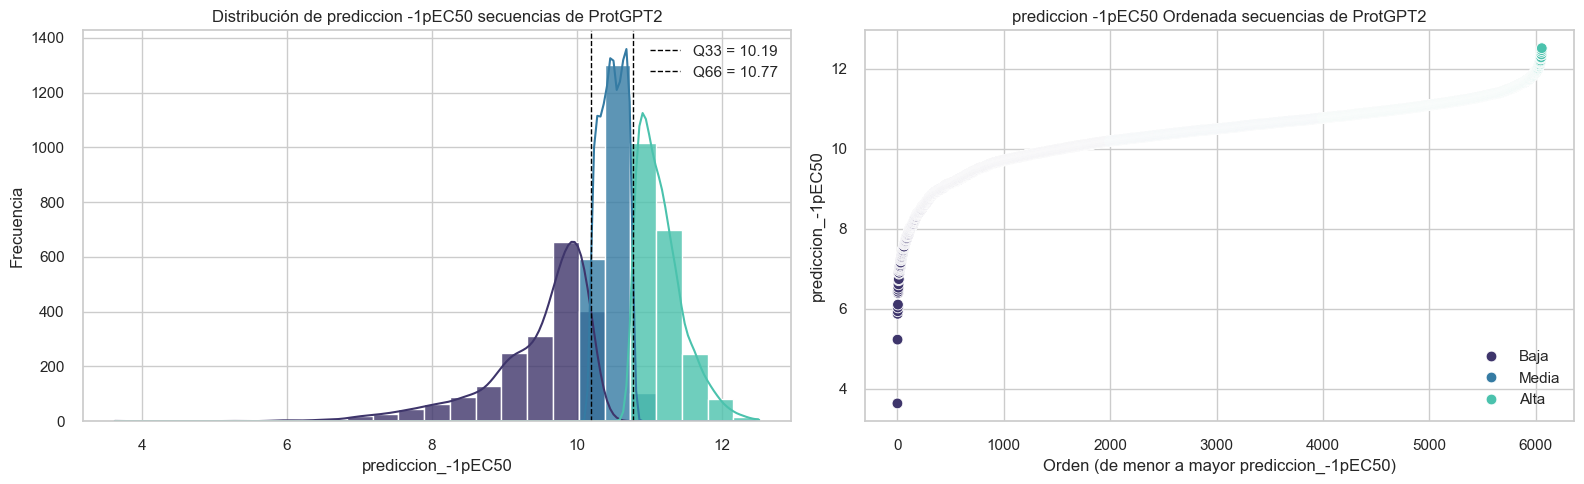


Resumen por categoría:
             n   promedio        min        max
Potencia                                       
Alta      2059  11.162811  10.765626  12.510620
Baja      1998   9.445616   3.632488  10.189529
Media     1998  10.489280  10.189554  10.765576

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
1791,secuencia_1792,12.510620,Alta
661,secuencia_662,12.462453,Alta
2573,secuencia_2574,12.418350,Alta
3794,secuencia_3795,12.354114,Alta
1256,secuencia_1257,12.353142,Alta
57,secuencia_58,12.351390,Alta
200,secuencia_201,12.281550,Alta
2139,secuencia_2140,12.268014,Alta
1573,secuencia_1574,12.264790,Alta
2447,secuencia_2448,12.260836,Alta


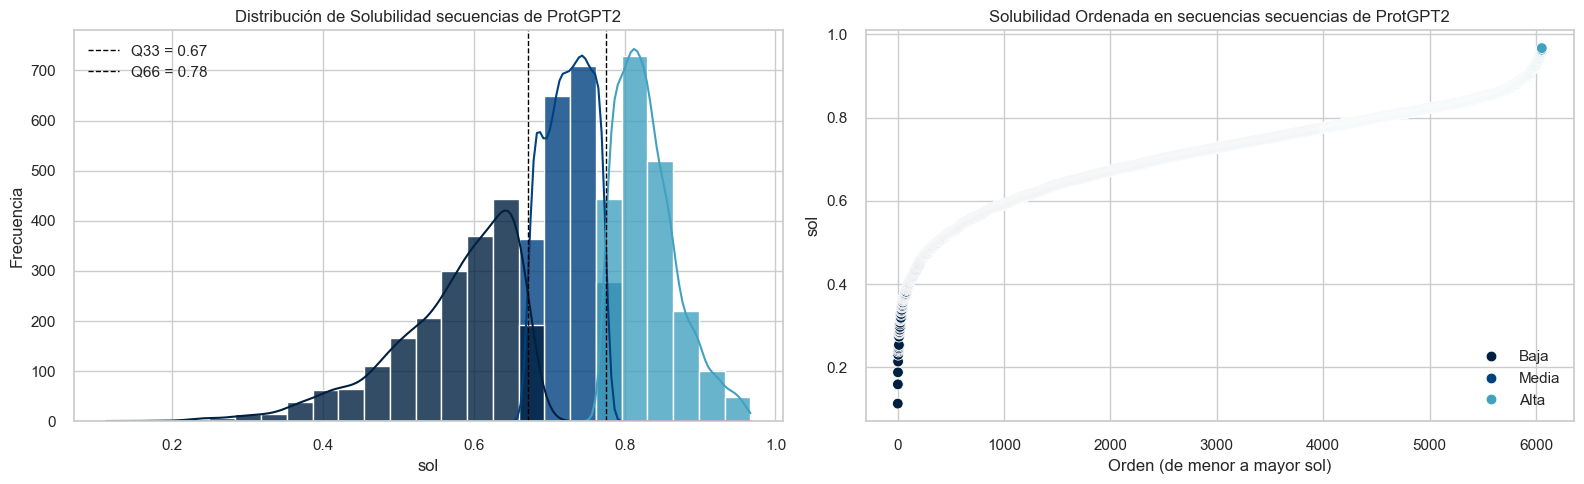


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      2059  0.830634  0.775160  0.966840
Baja      1998  0.570534  0.113008  0.671614
Media     1998  0.725952  0.671651  0.775038

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
5615,secuencia_5616,0.966840,Alta
1683,secuencia_1684,0.962960,Alta
2691,secuencia_2692,0.962539,Alta
2236,secuencia_2237,0.961214,Alta
3783,secuencia_3784,0.960760,Alta
6041,secuencia_6042,0.958687,Alta
1308,secuencia_1309,0.958606,Alta
595,secuencia_596,0.957026,Alta
2416,secuencia_2417,0.956653,Alta
624,secuencia_625,0.955533,Alta


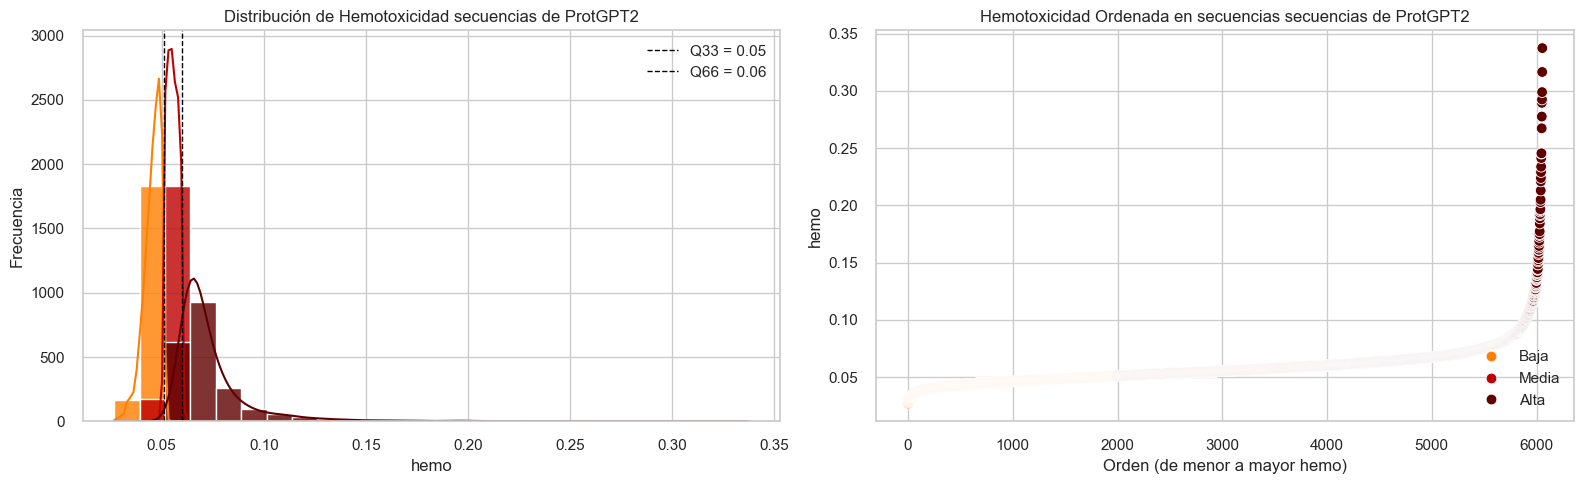


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      2059  0.075060  0.060078  0.337478
Baja      1998  0.045441  0.026779  0.050935
Media     1998  0.055359  0.050939  0.060075

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
2154,secuencia_2155,0.337478,Alta
3738,secuencia_3739,0.316619,Alta
5192,secuencia_5193,0.299024,Alta
4972,secuencia_4973,0.292589,Alta
1225,secuencia_1226,0.289655,Alta
867,secuencia_868,0.277656,Alta
2493,secuencia_2494,0.267378,Alta
5572,secuencia_5573,0.266973,Alta
3075,secuencia_3076,0.245551,Alta
3430,secuencia_3431,0.245286,Alta


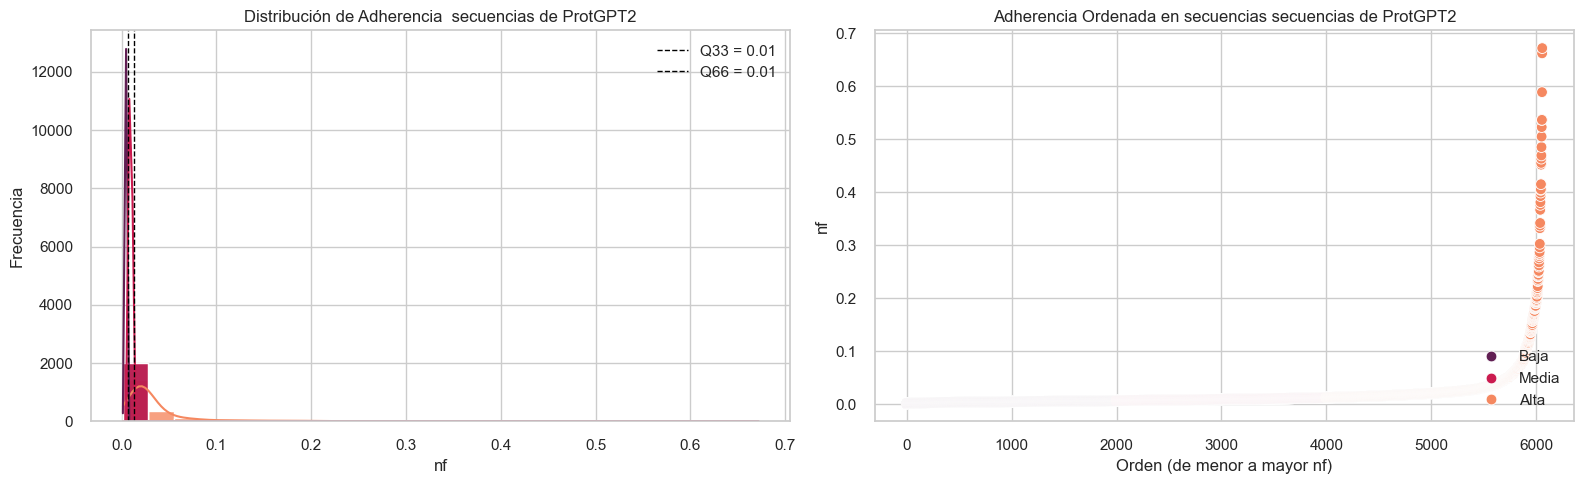


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      2059  0.040093  0.012853  0.671783
Baja      1998  0.004992  0.001454  0.007087
Media     1998  0.009645  0.007088  0.012848

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
4475,secuencia_4476,0.671783,Alta
1663,secuencia_1664,0.661928,Alta
3050,secuencia_3051,0.588733,Alta
1260,secuencia_1261,0.536464,Alta
723,secuencia_724,0.536382,Alta
2173,secuencia_2174,0.522840,Alta
718,secuencia_719,0.504972,Alta
5615,secuencia_5616,0.485135,Alta
1652,secuencia_1653,0.469414,Alta
2462,secuencia_2463,0.463368,Alta


In [33]:
# Generación de gráficos de las nuevas secuencias generadas con ProtGPT2
%matplotlib inline 

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protGPT2,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 secuencias de ProtGPT2',
    titulo_ordenado='prediccion -1pEC50 Ordenada secuencias de ProtGPT2')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protGPT2,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad secuencias de ProtGPT2',
    titulo_ordenado='Solubilidad Ordenada en secuencias secuencias de ProtGPT2'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protGPT2,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad secuencias de ProtGPT2',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias secuencias de ProtGPT2'
)

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protGPT2,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia  secuencias de ProtGPT2',
    titulo_ordenado='Adherencia Ordenada en secuencias secuencias de ProtGPT2'
)

## Generación de nuevas secuencias peptídicas agonistas de GLP-1 utilizando ProXLNET

### Modelo ProXLNet entrenado descongelando 10 capas de 30

In [34]:
# Genera time stamp

from datetime import datetime
# Generar timestamp en formato AñoMesDía_HoraMinutoSegundo
File_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

In [35]:
# Generación de nuevas secuencias usando ProtXLNet
variants = generate_with_protxlnet_pipeline(
    ruta_modelo_protxlnet = directorio_modelos / "prot_xlnet_finetuned",
    prompt_sequences=prompt_sequences,
    num_variants_per_seq=30,
    num_return_sequences=5,
    max_length=longitud_maxima,
    min_length=longitud_minima,
    top_k=50,
    repetition_penalty=1.0,
)
df_secuencias_protxlnet = pd.DataFrame(variants, columns=["sequence"])


Usando dispositivo: cuda
Cargando tokenizer de ProtXLNet...
Cargando pipeline de generación...


Loading weights:   0%|          | 0/513 [00:00<?, ?it/s]

Pipeline cargado.
Preparando las secuencias iniciales...


  0%|          | 0/68 [00:00<?, ?it/s]

Generando 2005 variantes (el pipeline manejará los lotes)...
Procesando salidas...


Procesando:   0%|          | 0/2005 [00:00<?, ?it/s]


Generación completada. Se obtuvieron 3447 variantes únicas.


In [36]:
# Ajuste de las secuencias y filtrado
allowed_chars = "ACDEFGHIKLMNPQRSTVWY"
pattern_to_remove = f"[^{allowed_chars}]"

df_secuencias_protxlnet['sequence'] = df_secuencias_protxlnet['sequence'].str.replace(pattern_to_remove, '', regex=True)
                        
df_secuencias_protxlnet['ID'] = [f"secuencia_{idx}" for idx in range(1, len(df_secuencias_protxlnet) + 1)]
df_secuencias_protxlnet = df_secuencias_protxlnet[['ID', 'sequence']]
df_secuencias_protxlnet.head(10)

,ID,sequence
0,secuencia_1,HADGTFTSDVSSDLTDQAIRDFVARLKAGR
1,secuencia_2,HADGHFTSDYYYY
2,secuencia_3,HSQGTFTSDYSKYLEEEAVRLFICWLMST
3,secuencia_4,HAEGTFTSDVSSYLKDQAIKDAVAKLKSGQ
4,secuencia_5,HADGTFTSDVSSYLKDQLIKDFSARLKSGQYYY
5,secuencia_6,YSEGTFKKS
6,secuencia_7,HAEGTFTSDVSAYLEGQAAKEFIPWLVKGRYYYYYYY
7,secuencia_8,YSEGTFLSDYSKLKEEEANRLFIEWLLAGGPSSGAPPPS
8,secuencia_9,YSEGTFTSDYSKLKEEEANRLFIEWLLAGPPSSGAPPPS
9,secuencia_10,HADGEFTSDVSSYLKDQLIKDFVARLKSGQ


#### Cálculo de las características necesarias para la predicción de la actividad biológica

In [37]:
# Cálculo de descriptores y actividad biológica predicha para las nuevas secuencias generadas con ProtXLNET

df_secuencias_protxlnet = calcular_descriptores_ifeature(
        directorio_temporal=directorio_temporal,
        dataframe=df_secuencias_protxlnet,
        sequence_col='sequence',
        id_col='ID',
        descriptores=descriptores,
        ifeatures_settings_json=ifeatures_settings_json
    )
    
# Calculo de pEC50 sobre los datos de alpha fold y uniprot
df_secuencias_protxlnet = predict_model(modelo_pycaret, data=df_secuencias_protxlnet)
df_secuencias_protxlnet.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para el conjunto obtenido de la base de datos de Aphafold
df_secuencias_protxlnet = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_secuencias_protxlnet, 
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)

Success! DataFrame has been saved to 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132723.fasta'.
Inspecting file: d:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132723.fasta...
  - OK! File is structurally valid. Found 3447 records.
'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132723.fasta' es válido. Se encontraron 3447 registros.
Iniciando cálculo de 14 descriptores...


calculando descriptores:   0%|          | 0/14 [00:00<?, ?it/s]

File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
Cálculo de descriptores finalizado.
Descriptores unidos al DataFrame. Forma final: (3447, 1292)
Archivo temporal 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_132723.fasta' eliminado.
Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


...

Procesando caracteristica: sol


  0%|          | 0/3447 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/3447 [00:00<?, ?it/s]

In [38]:
# guardar en un archivo CSV las nuevas secuencias generadas

# Guardar df_secuencias_nuevas en CSV con timestamp

nombre_archivo = f"secuencias_nuevas_protxlnet_{File_timestamp}"
nombre_archivo_csv = f"{nombre_archivo}.csv"

In [39]:
# Guardar el DataFrame en CSV
ruta_salida_secuencias_nuevas = Path(directorio_nuevas_secuencias /nombre_archivo_csv)

df_secuencias_protxlnet.to_csv(ruta_salida_secuencias_nuevas, index=False)
print(f"Archivo guardado: {ruta_salida_secuencias_nuevas}")

Archivo guardado: d:\source\Proyecto Integrador\glp-1_drug_discovery\data\processed\Actividad_5\secuencias_nuevas\secuencias_nuevas_protxlnet_20260316_132559.csv


### Resultados de la generación de nuevas secuencias con ProXLNET 

In [40]:
#Top  de secuencias generadas por propiedades deseadas 
df_secuencias_protxlnet.sort_values(by=['prediccion_-1pEC50','sol','hemo','nf'], ascending=[False, False, True, True], inplace=True)
df_secuencias_protxlnet[["ID","sequence","sol","hemo", "nf","prediccion_-1pEC50"]].head()

,ID,sequence,sol,hemo,nf,prediccion_-1pEC50
2345,secuencia_2346,HSQGA,0.810979,0.051236,0.523750,13.696948
3119,secuencia_3120,YSEGHF,0.800077,0.047602,0.374940,13.478973
1917,secuencia_1918,HSQGH,0.901575,0.043776,0.526376,13.305611
1854,secuencia_1855,YSEGV,0.857886,0.093376,0.436680,13.286900
940,secuencia_941,HSQGAY,0.758727,0.041830,0.454167,12.948855


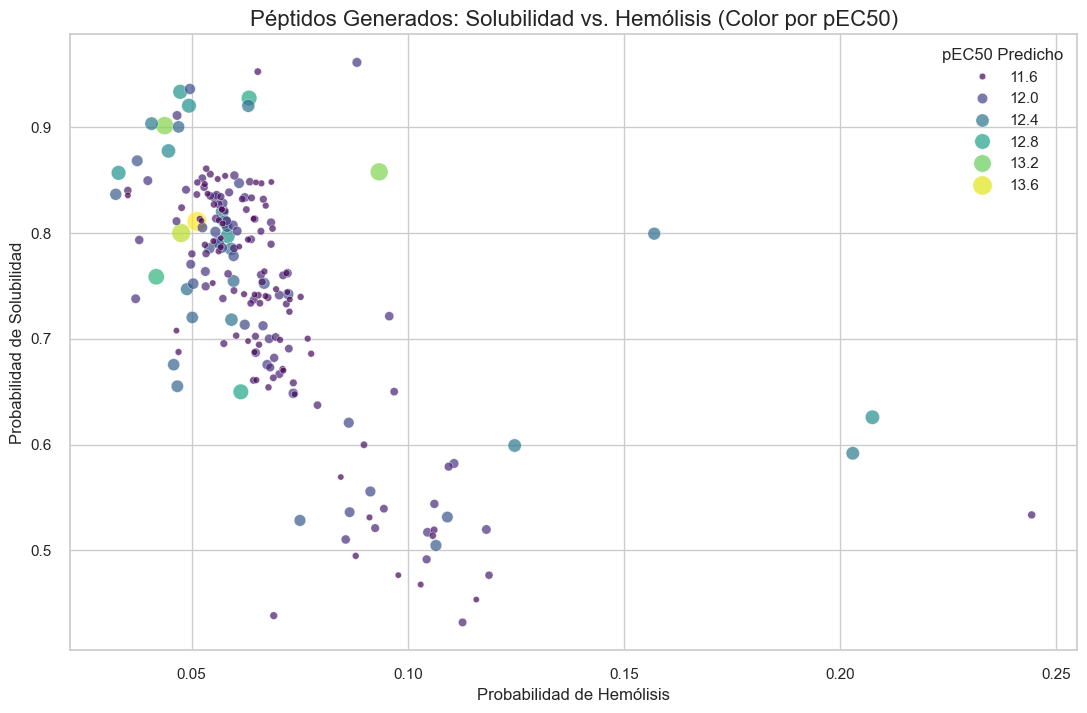

In [41]:
## Visualización de las propiedades predichas: Hemólisis vs Solubilidad coloreado por pEC50

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Crear el gráfico de dispersión
plt.figure(figsize=(13, 8))
scatter = sns.scatterplot(
    data=df_secuencias_protxlnet.head(200), # Mostrar solo las 200 secuencias con mayor pEC50
    x='hemo',
    y='sol',
    hue='prediccion_-1pEC50',
    palette='viridis', # Usamos un mapa de color "viridis" donde los colores más claros indican valores más altos
    size='prediccion_-1pEC50', # El tamaño del punto también representará el pEC50
    sizes=(20, 200),
    alpha=0.7,
    edgecolor='w'
)

# Añadir títulos y etiquetas
plt.title('Péptidos Generados: Solubilidad vs. Hemólisis (Color por pEC50)', fontsize=16)
plt.xlabel('Probabilidad de Hemólisis', fontsize=12)
plt.ylabel('Probabilidad de Solubilidad', fontsize=12)
plt.legend(title='pEC50 Predicho')
plt.grid(True)

# Mostrar el gráfico
plt.show()

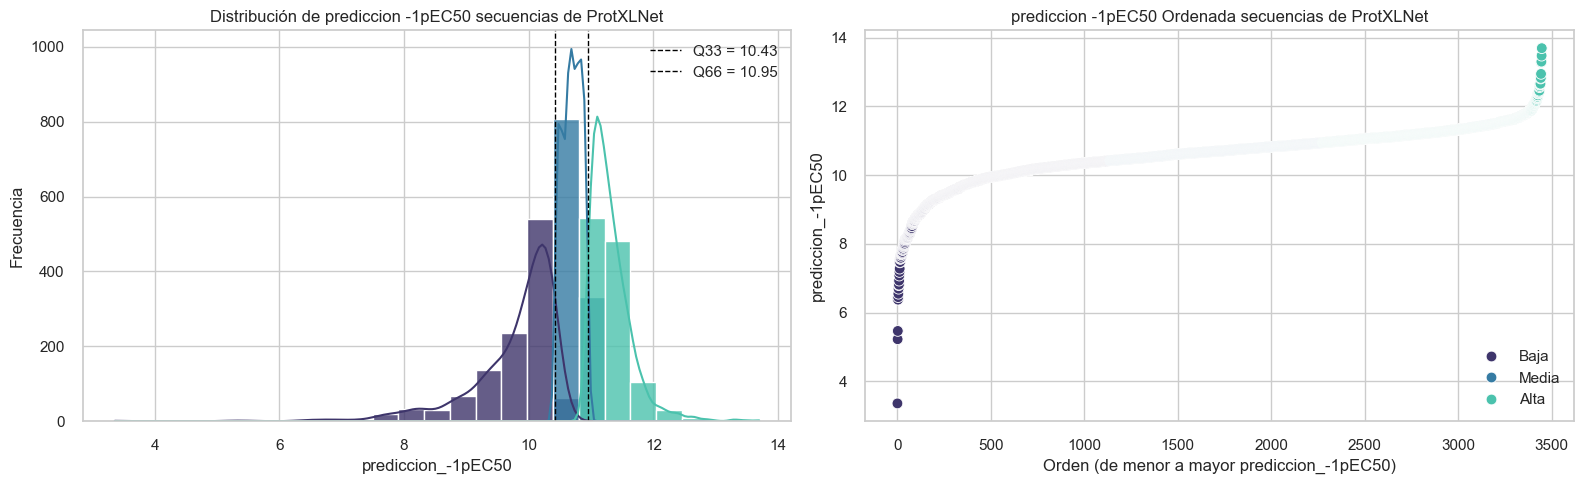


Resumen por categoría:
             n   promedio        min        max
Potencia                                       
Alta      1172  11.319215  10.946215  13.696948
Baja      1138   9.771594   3.359490  10.426464
Media     1137  10.692491  10.427109  10.946181

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
2345,secuencia_2346,13.696948,Alta
3119,secuencia_3120,13.478973,Alta
1917,secuencia_1918,13.305611,Alta
1854,secuencia_1855,13.286900,Alta
940,secuencia_941,12.948855,Alta
1325,secuencia_1326,12.830953,Alta
3359,secuencia_3360,12.814935,Alta
3443,secuencia_3444,12.663201,Alta
68,secuencia_69,12.651577,Alta
1288,secuencia_1289,12.650879,Alta


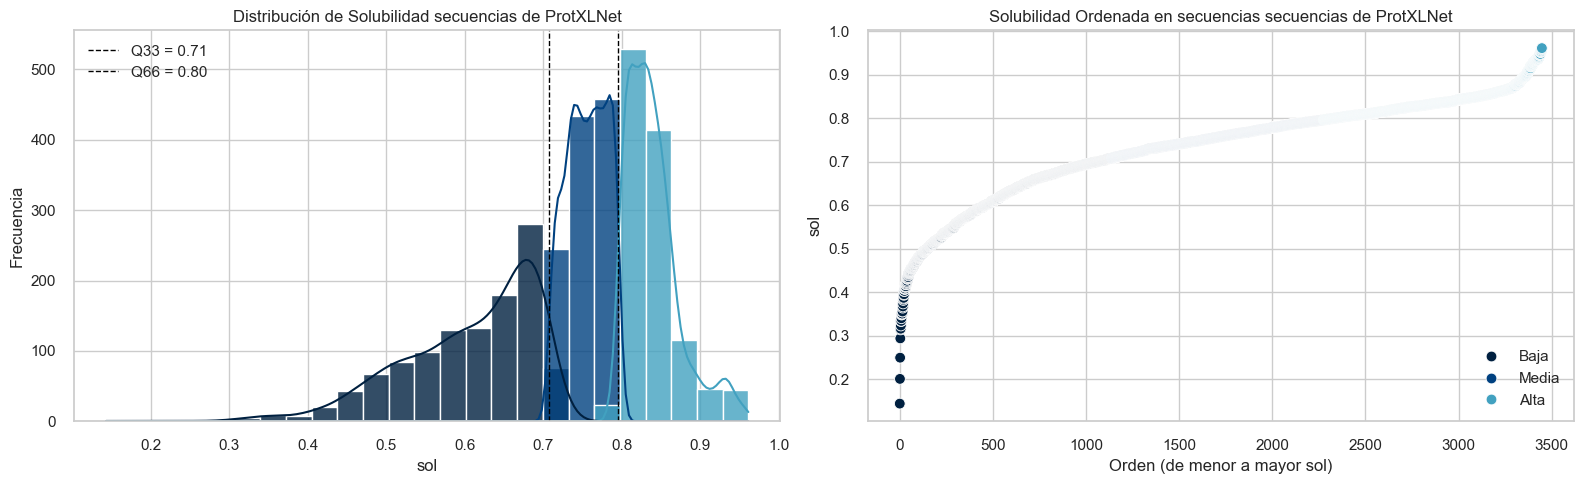


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      1172  0.839631  0.795954  0.961360
Baja      1138  0.605111  0.143426  0.708021
Media     1137  0.755577  0.708057  0.795934

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
676,secuencia_677,0.961360,Alta
2464,secuencia_2465,0.960440,Alta
2497,secuencia_2498,0.958561,Alta
1943,secuencia_1944,0.956911,Alta
2500,secuencia_2501,0.954549,Alta
2634,secuencia_2635,0.953444,Alta
3205,secuencia_3206,0.952625,Alta
358,secuencia_359,0.952553,Alta
2558,secuencia_2559,0.952510,Alta
1281,secuencia_1282,0.947937,Alta


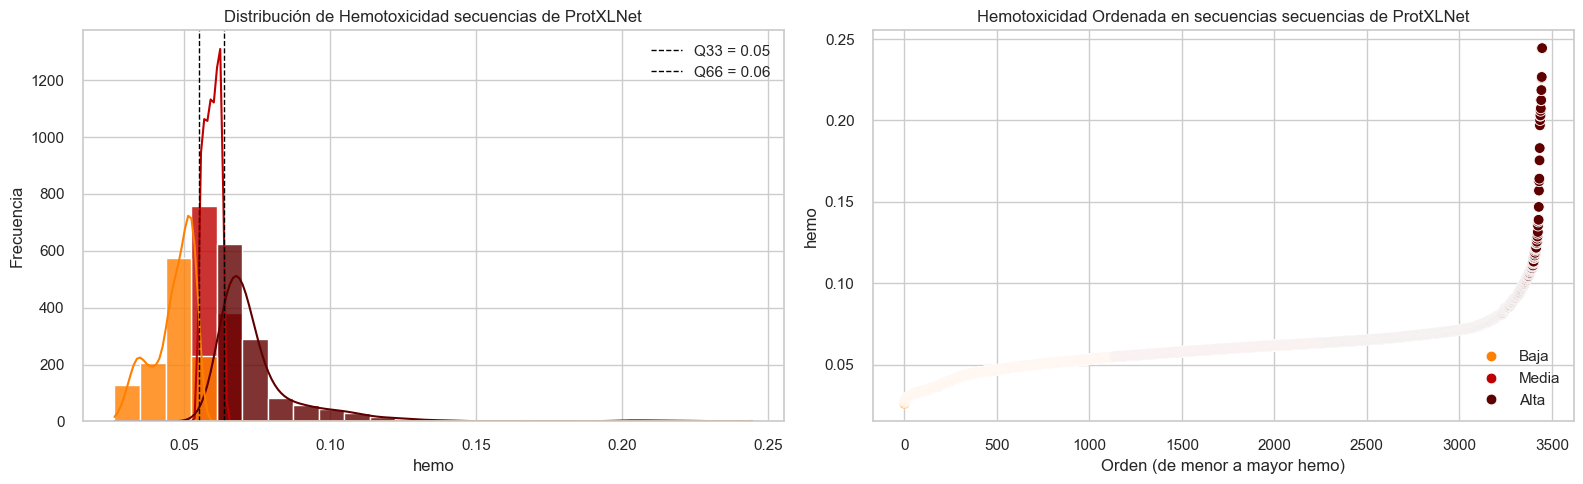


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      1172  0.076073  0.063629  0.244436
Baja      1138  0.046173  0.026208  0.054989
Media     1137  0.059549  0.055000  0.063621

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
1859,secuencia_1860,0.244436,Alta
3106,secuencia_3107,0.244272,Alta
2316,secuencia_2317,0.226718,Alta
780,secuencia_781,0.226191,Alta
79,secuencia_80,0.218673,Alta
1254,secuencia_1255,0.212514,Alta
1802,secuencia_1803,0.212382,Alta
1539,secuencia_1540,0.207445,Alta
2293,secuencia_2294,0.205919,Alta
668,secuencia_669,0.203112,Alta


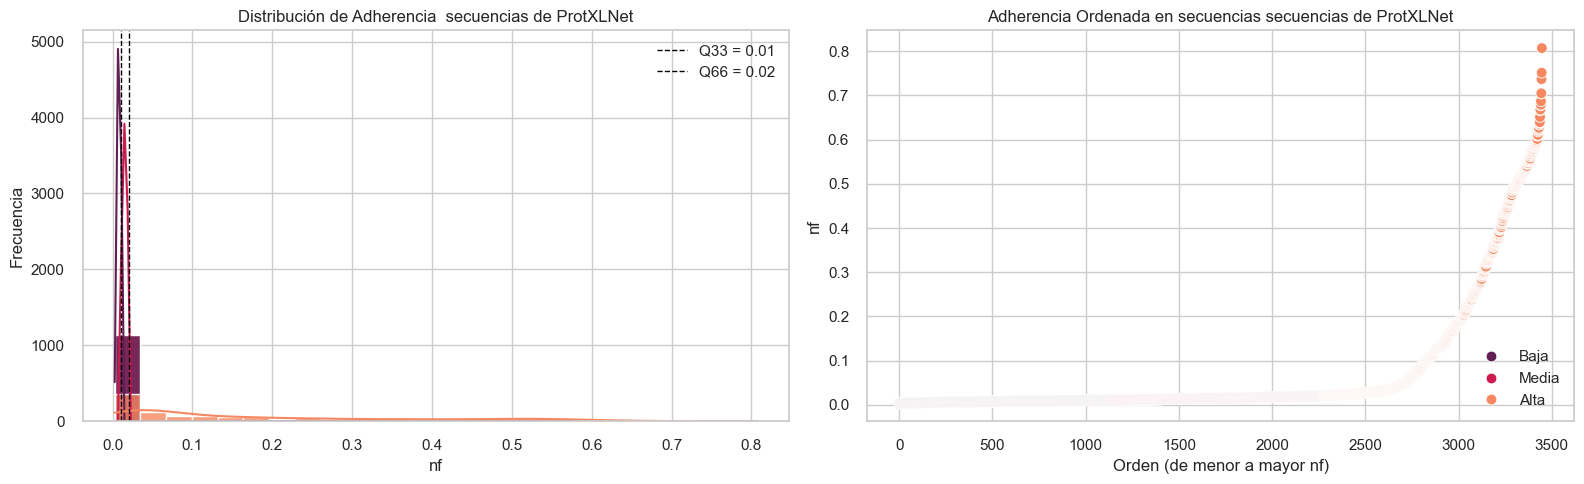


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      1172  0.192232  0.020925  0.807137
Baja      1138  0.007649  0.002719  0.010989
Media     1137  0.015118  0.010995  0.020914

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
1020,secuencia_1021,0.807137,Alta
1154,secuencia_1155,0.751527,Alta
1511,secuencia_1512,0.736904,Alta
3405,secuencia_3406,0.704811,Alta
2558,secuencia_2559,0.704526,Alta
2159,secuencia_2160,0.686828,Alta
178,secuencia_179,0.679058,Alta
358,secuencia_359,0.677619,Alta
879,secuencia_880,0.668093,Alta
2077,secuencia_2078,0.666203,Alta


In [42]:
# Generación de gráficos de las nuevas secuencias generadas con ProtXLNet
%matplotlib inline 

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 secuencias de ProtXLNet',
    titulo_ordenado='prediccion -1pEC50 Ordenada secuencias de ProtXLNet')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad secuencias de ProtXLNet',
    titulo_ordenado='Solubilidad Ordenada en secuencias secuencias de ProtXLNet'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad secuencias de ProtXLNet',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias secuencias de ProtXLNet'
)

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia  secuencias de ProtXLNet',
    titulo_ordenado='Adherencia Ordenada en secuencias secuencias de ProtXLNet'
)

### ProXLNet entrenado con peptidos GLP-1 sobre 8 capas

In [43]:
from datetime import datetime
# Generar timestamp en formato AñoMesDía_HoraMinutoSegundo
File_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')


In [44]:
variants = generate_with_protxlnet_pipeline(
    ruta_modelo_protxlnet = directorio_modelos / "prot_xlnet",
    prompt_sequences=prompt_sequences,
    num_variants_per_seq=30,
    num_return_sequences=5,
    max_length=longitud_maxima,
    min_length=longitud_minima,
    top_k=50,
    repetition_penalty=1.0,
)
df_secuencias_protxlnet_8 = pd.DataFrame(variants, columns=["sequence"])


Usando dispositivo: cuda
Cargando tokenizer de ProtXLNet...
Cargando pipeline de generación...


Loading weights:   0%|          | 0/514 [00:00<?, ?it/s]

Pipeline cargado.
Preparando las secuencias iniciales...


  0%|          | 0/68 [00:00<?, ?it/s]

Generando 2011 variantes (el pipeline manejará los lotes)...
Procesando salidas...


Procesando:   0%|          | 0/2011 [00:00<?, ?it/s]


Generación completada. Se obtuvieron 9753 variantes únicas.


In [45]:
# Limpiar valors no validos
allowed_chars = "ACDEFGHIKLMNPQRSTVWY"
pattern_to_remove = f"[^{allowed_chars}]"

df_secuencias_protxlnet_8['sequence'] = df_secuencias_protxlnet_8['sequence'].str.replace(pattern_to_remove, '', regex=True)
                        
df_secuencias_protxlnet_8['ID'] = [f"secuencia_{idx}" for idx in range(1, len(df_secuencias_protxlnet_8) + 1)]
df_secuencias_protxlnet_8 = df_secuencias_protxlnet_8[['ID', 'sequence']]
df_secuencias_protxlnet_8.head(10)

,ID,sequence
0,secuencia_1,HSEGTFTSDFSSYLDYKATKEFIAQLTKGTNNVYEHNNYH
1,secuencia_2,HGEGTFTSDVSSYMERQSVDEFIAWLLKGWNEYHNNHYNY
2,secuencia_3,HADGTFTSDVSSYLKDQLIKDFVARLKAMQYVYNYNVYYN
3,secuencia_4,HSQGTFTSDYSKYLEEEAVRLFICILMNTVNYHHDYYHN
4,secuencia_5,YAEGTFRSDYSIYLDEIAAQEFVNWLLAGGPSSGAPPPSNH
5,secuencia_6,HSQGTFTIDYSKYLDSRRASEFVQWLIAENYMYYDHNYN
6,secuencia_7,HADGTFTSDVAAYLKEQAIKDFVAKLKSGQDYVVNEYNND
7,secuencia_8,HADGTFTSDVSSYLKDQMIKDFVAKLKSGEKNVHNQYYDY
8,secuencia_9,HAEGTFTSDVSSVLEGQAAKEFIAWLVGRNEYDRHNVNH
9,secuencia_10,HSQGTFTVDYSKYIEHTYNQDYY


In [46]:
# Cálculo de descriptores y actividad biológica predicha para las nuevas secuencias generadas con ProtXLNET

df_secuencias_protxlnet_8 = calcular_descriptores_ifeature(
        directorio_temporal=directorio_temporal,
        dataframe=df_secuencias_protxlnet_8,
        sequence_col='sequence',
        id_col='ID',
        descriptores=descriptores,
        ifeatures_settings_json=ifeatures_settings_json
    )
    
# Calculo de pEC50 sobre los datos de alpha fold y uniprot
df_secuencias_protxlnet_8 = predict_model(modelo_pycaret, data=df_secuencias_protxlnet_8)
df_secuencias_protxlnet_8.rename(columns={'prediction_label': 'prediccion_-1pEC50'}, inplace=True)
# Predicciones con PeptideBert para el conjunto obtenido de la base de datos de Aphafold
df_secuencias_protxlnet_8 = predict_peptidebert(
    directorio_modelos_peptidebert,
    df_secuencias_protxlnet_8,
    sequence_col='sequence',  # Le dices qué columna usar
    feats=['hemo', 'sol', 'nf']
)

Success! DataFrame has been saved to 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_133109.fasta'.
Inspecting file: d:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_133109.fasta...
  - OK! File is structurally valid. Found 9753 records.
'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_133109.fasta' es válido. Se encontraron 9753 registros.
Iniciando cálculo de 14 descriptores...


calculando descriptores:   0%|          | 0/14 [00:00<?, ?it/s]

File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
File imported successfully.
Cálculo de descriptores finalizado.
Descriptores unidos al DataFrame. Forma final: (9753, 1292)
Archivo temporal 'd:\source\Proyecto Integrador\glp-1_drug_discovery\temp\ifeature_input_20260316_133109.fasta' eliminado.
Usando dispositivo: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: hemo


...

Procesando caracteristica: sol


  0%|          | 0/9753 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Procesando caracteristica: nf


  0%|          | 0/9753 [00:00<?, ?it/s]

In [47]:
# guardar en un archivo CSV las nuevas secuencias generadas

# Guardar df_secuencias_nuevas en CSV con timestamp

nombre_archivo = f"secuencias_nuevas_protxlnet_8{File_timestamp}"
nombre_archivo_csv = f"{nombre_archivo}.csv"

# Guardar el DataFrame en CSV
ruta_salida_secuencias_nuevas = Path(directorio_nuevas_secuencias /nombre_archivo_csv)

df_secuencias_protxlnet_8.to_csv(ruta_salida_secuencias_nuevas, index=False)
print(f"Archivo guardado: {ruta_salida_secuencias_nuevas}")

Archivo guardado: d:\source\Proyecto Integrador\glp-1_drug_discovery\data\processed\Actividad_5\secuencias_nuevas\secuencias_nuevas_protxlnet_820260316_132950.csv


### Resultados de la generación de nuevas secuencias con ProXLNET 

In [48]:
#Top  de secuencias generadas por propiedades deseadas 
df_secuencias_protxlnet_8.sort_values(by=['prediccion_-1pEC50','sol','hemo','nf'], ascending=[False, False, True, True], inplace=True)
df_secuencias_protxlnet_8[["ID","sequence","sol","hemo", "nf","prediccion_-1pEC50"]].head()

,ID,sequence,sol,hemo,nf,prediccion_-1pEC50
5816,secuencia_5817,HYDGTFTSDVSAYLKVYVHDYHMNV,0.762194,0.048831,0.017508,12.332153
61,secuencia_62,HADGTFTSDVSAYLKSQAIKDFVNRYVHDHVYAYN,0.667783,0.043289,0.007496,12.085537
2027,secuencia_2028,HSIGTFTSDYSAYLDSRRASEFVQWLISENVYVYDNAYV,0.539570,0.055594,0.004537,12.070444
5078,secuencia_5079,HADGTFTSDVSAYLKEQAIKDFVAKMKAGQYNYVHAYVHD,0.721578,0.041397,0.005775,12.022733
7175,secuencia_7176,HADGTFTSDVSAYLKEQAIKDFVAKLKADQNIYTYYDYHY,0.615170,0.045440,0.005014,11.968495


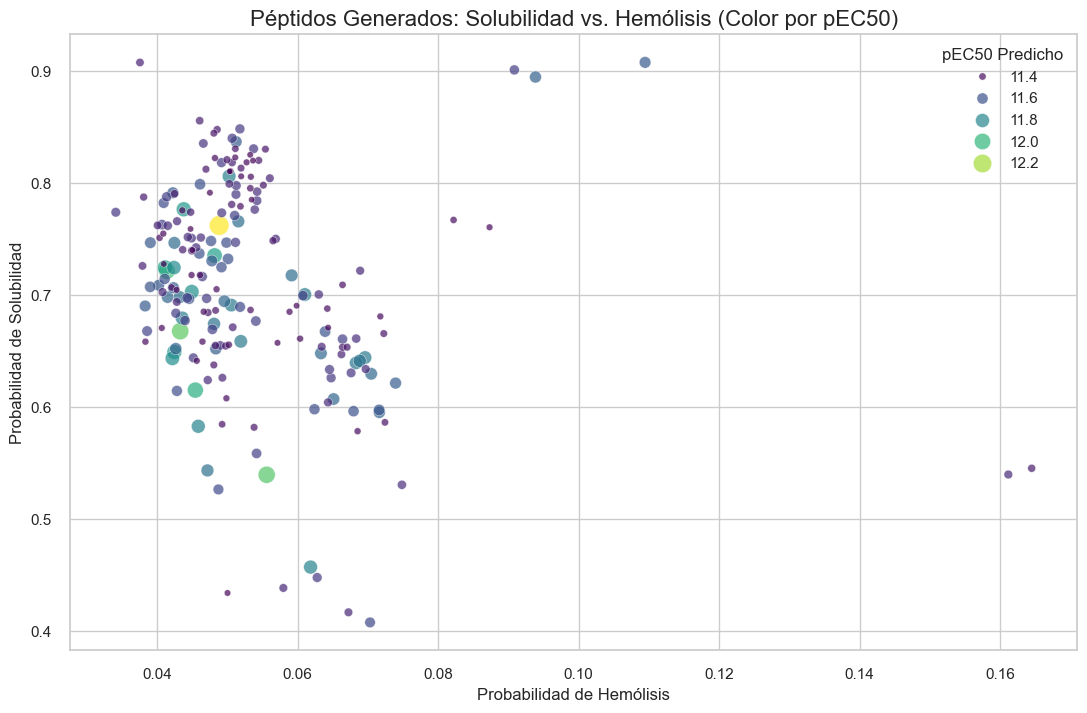

In [49]:
## Visualización de las propiedades predichas: Hemólisis vs Solubilidad coloreado por pEC50

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Crear el gráfico de dispersión
plt.figure(figsize=(13, 8))
scatter = sns.scatterplot(
    data=df_secuencias_protxlnet_8.head(200), # Mostrar solo las 200 secuencias con mayor pEC50
    x='hemo',
    y='sol',
    hue='prediccion_-1pEC50',
    palette='viridis', # Usamos un mapa de color "viridis" donde los colores más claros indican valores más altos
    size='prediccion_-1pEC50', # El tamaño del punto también representará el pEC50
    sizes=(20, 200),
    alpha=0.7,
    edgecolor='w'
)

# Añadir títulos y etiquetas
plt.title('Péptidos Generados: Solubilidad vs. Hemólisis (Color por pEC50)', fontsize=16)
plt.xlabel('Probabilidad de Hemólisis', fontsize=12)
plt.ylabel('Probabilidad de Solubilidad', fontsize=12)
plt.legend(title='pEC50 Predicho')
plt.grid(True)

# Mostrar el gráfico
plt.show()

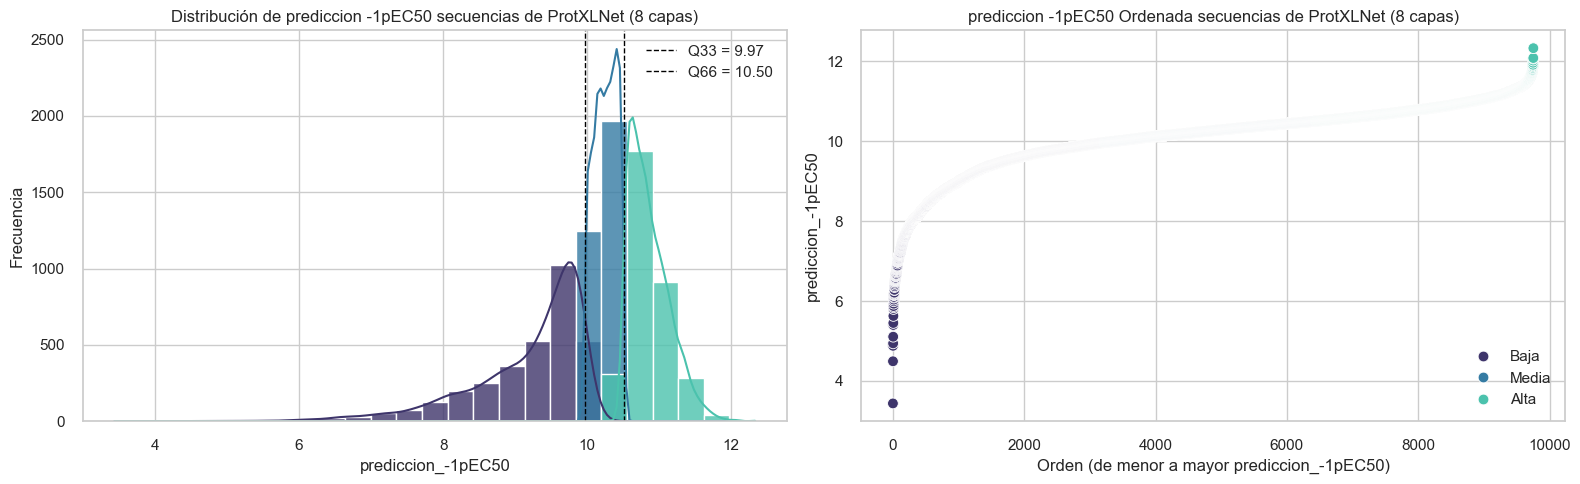


Resumen por categoría:
             n   promedio        min        max
Potencia                                       
Alta      3316  10.866012  10.505022  12.332153
Baja      3219   9.171670   3.437242   9.969684
Media     3218  10.252515   9.969883  10.504828

Top 15 registros de categoría "Alta":


,ID,prediccion_-1pEC50,Potencia
5816,secuencia_5817,12.332153,Alta
61,secuencia_62,12.085537,Alta
2027,secuencia_2028,12.070444,Alta
5078,secuencia_5079,12.022733,Alta
7175,secuencia_7176,11.968495,Alta
9445,secuencia_9446,11.919668,Alta
5307,secuencia_5308,11.901384,Alta
7677,secuencia_7678,11.875039,Alta
6037,secuencia_6038,11.872754,Alta
4439,secuencia_4440,11.843600,Alta


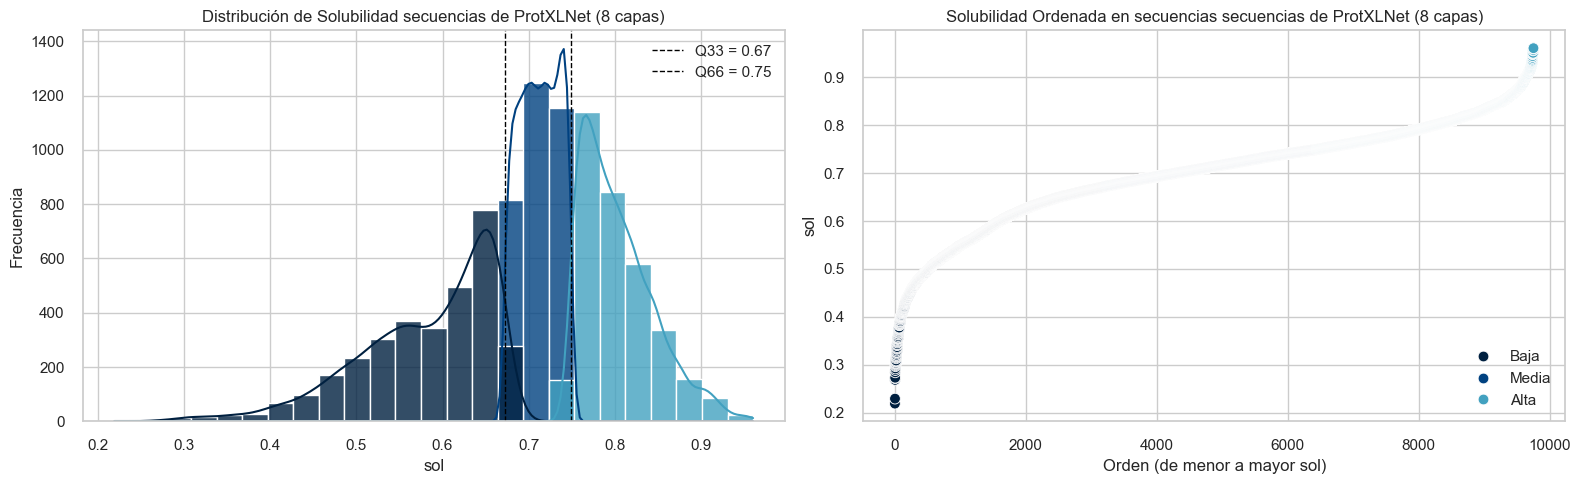


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      3316  0.803629  0.748976  0.960451
Baja      3219  0.579726  0.219279  0.672088
Media     3218  0.712249  0.672113  0.748966

Top 15 registros de categoría "Alta":


,ID,sol,Potencia
4747,secuencia_4748,0.960451,Alta
2704,secuencia_2705,0.960216,Alta
9031,secuencia_9032,0.959978,Alta
8548,secuencia_8549,0.956791,Alta
4982,secuencia_4983,0.955842,Alta
6591,secuencia_6592,0.950880,Alta
2965,secuencia_2966,0.950224,Alta
9516,secuencia_9517,0.949698,Alta
3011,secuencia_3012,0.949569,Alta
931,secuencia_932,0.949429,Alta


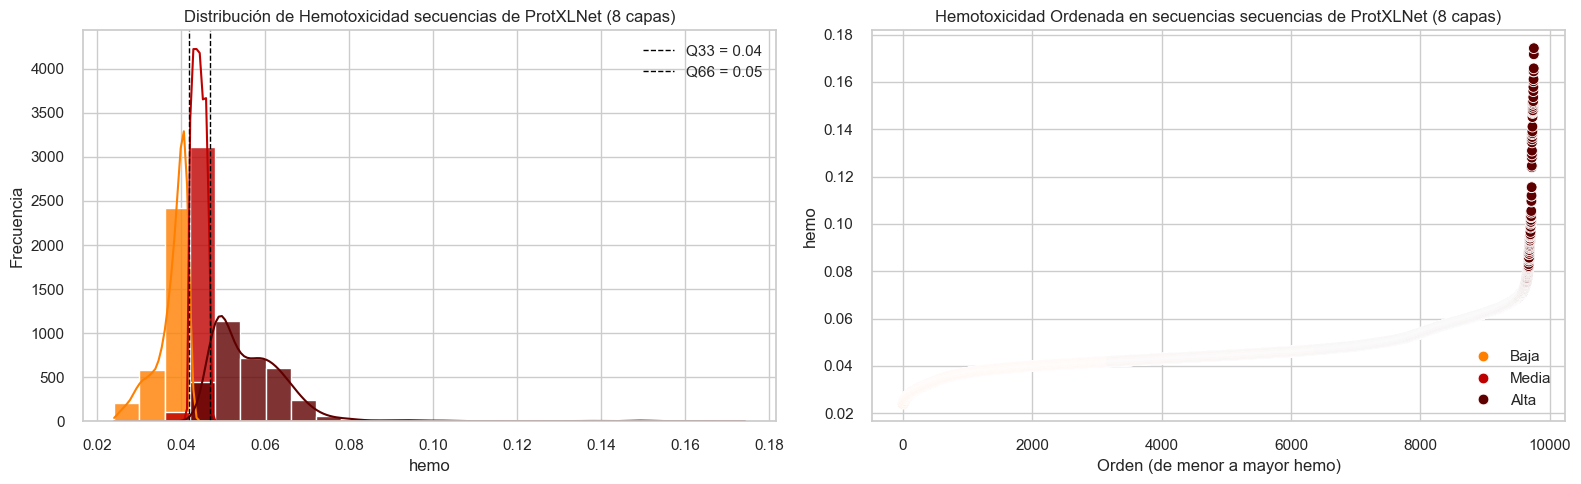


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      3316  0.057433  0.047014  0.174279
Baja      3219  0.037770  0.024096  0.041954
Media     3218  0.044306  0.041955  0.047010

Top 15 registros de categoría "Alta":


,ID,hemo,Potencia
7034,secuencia_7035,0.174279,Alta
4539,secuencia_4540,0.171695,Alta
4576,secuencia_4577,0.165753,Alta
4253,secuencia_4254,0.164491,Alta
1857,secuencia_1858,0.164436,Alta
1031,secuencia_1032,0.161162,Alta
4613,secuencia_4614,0.160288,Alta
9644,secuencia_9645,0.157898,Alta
6387,secuencia_6388,0.156110,Alta
6342,secuencia_6343,0.153576,Alta


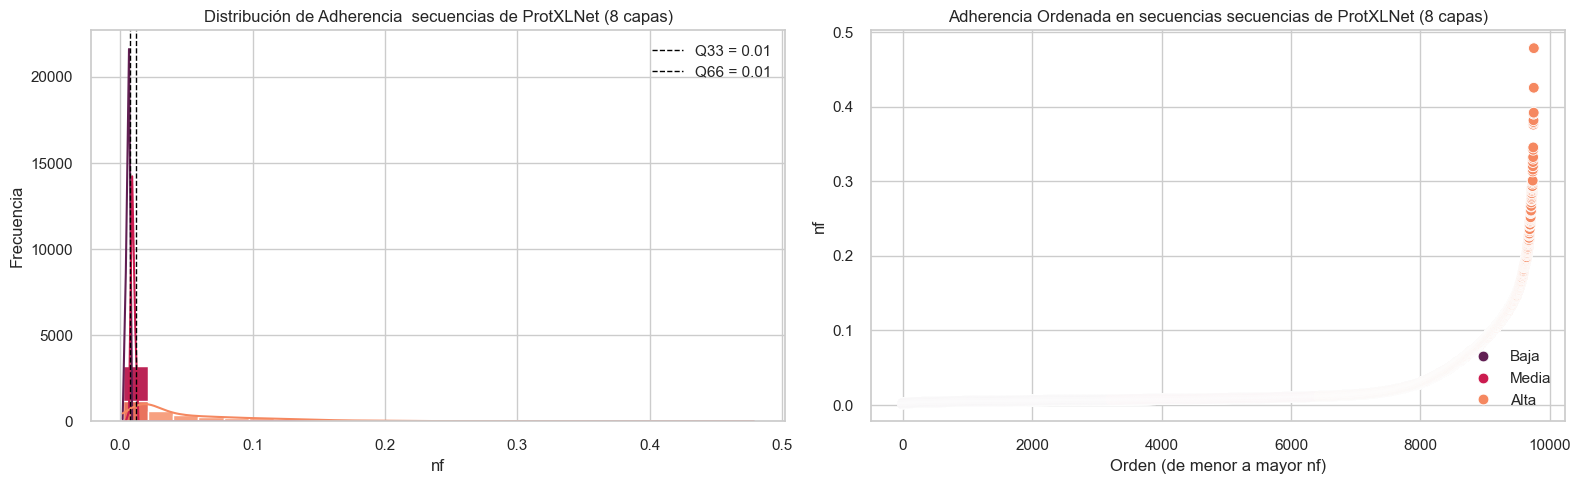


Resumen por categoría:
             n  promedio       min       max
Potencia                                    
Alta      3316  0.058296  0.011610  0.478369
Baja      3219  0.005479  0.001860  0.007117
Media     3218  0.008894  0.007117  0.011607

Top 15 registros de categoría "Alta":


,ID,nf,Potencia
9592,secuencia_9593,0.478369,Alta
2962,secuencia_2963,0.425336,Alta
665,secuencia_666,0.391922,Alta
3964,secuencia_3965,0.390746,Alta
6127,secuencia_6128,0.390690,Alta
7326,secuencia_7327,0.381713,Alta
7515,secuencia_7516,0.379449,Alta
3802,secuencia_3803,0.378056,Alta
673,secuencia_674,0.375853,Alta
4328,secuencia_4329,0.345335,Alta


In [50]:
# Generación de gráficos de las nuevas secuencias generadas con ProtXLNet
%matplotlib inline 

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet_8,   columna_valor='prediccion_-1pEC50', 
    columna_id='ID', top_n=15,palette='mako',
    titulo_distribucion='Distribución de prediccion -1pEC50 secuencias de ProtXLNet (8 capas)',
    titulo_ordenado='prediccion -1pEC50 Ordenada secuencias de ProtXLNet (8 capas)')    
    
clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet_8,   columna_valor='sol', 
    columna_id='ID', top_n=15,palette='ocean',
    titulo_distribucion='Distribución de Solubilidad secuencias de ProtXLNet (8 capas)',
    titulo_ordenado='Solubilidad Ordenada en secuencias secuencias de ProtXLNet (8 capas)'
)    

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet_8,   columna_valor='hemo', 
    columna_id='ID', top_n=15,palette='gist_heat_r',
    titulo_distribucion='Distribución de Hemotoxicidad secuencias de ProtXLNet (8 capas)',
    titulo_ordenado='Hemotoxicidad Ordenada en secuencias secuencias de ProtXLNet (8 capas)'
)

clasificar_y_graficar_cuantiles(
    df_input=df_secuencias_protxlnet_8,   columna_valor='nf', 
    columna_id='ID', top_n=15, palette='rocket',
    titulo_distribucion='Distribución de Adherencia  secuencias de ProtXLNet (8 capas)',
    titulo_ordenado='Adherencia Ordenada en secuencias secuencias de ProtXLNet (8 capas)'
)

### Análisis de resultados con de ProXLNet

Los resultados de ProXLNet muestran mejores características de actividad biológica, esto se debe a que tiende a completar las secuencias repitiendo aminoácidos más que intentar generar secuencias nuevas, aunque las secuencias que se obtienen repiten aminoácidos y tienen menor diversidad y por lo tanto hay menos secuencias únicas, el modelo predictivo indica mejoras en la actividad eP50 al actuar de forma conservadora con el prompt.

El modelo al que se entreno descongelando 10 capas tuvo mejor desempeño aunque marginal respecto a modelo que se entreno descongelando 8 capas


# Comparativa de resultados

En el siguiente gráfico se muestran los datos correspondientes a los 3 modelos de lenguaje utilizados para la generación de nuevas secuencias peptídicas: ProtGPT2, ProXLNet con 10 capas descongeladas y ProXLNet con 8 capas descongeladas. Cada punto en el gráfico representa una secuencia generada, y el color indica la predicción de actividad biológica (-1pEC50) obtenida mediante el modelo predictivo entrenado previamente.

Se aprecia que ProXLNet obtuvo mejores resultados en general

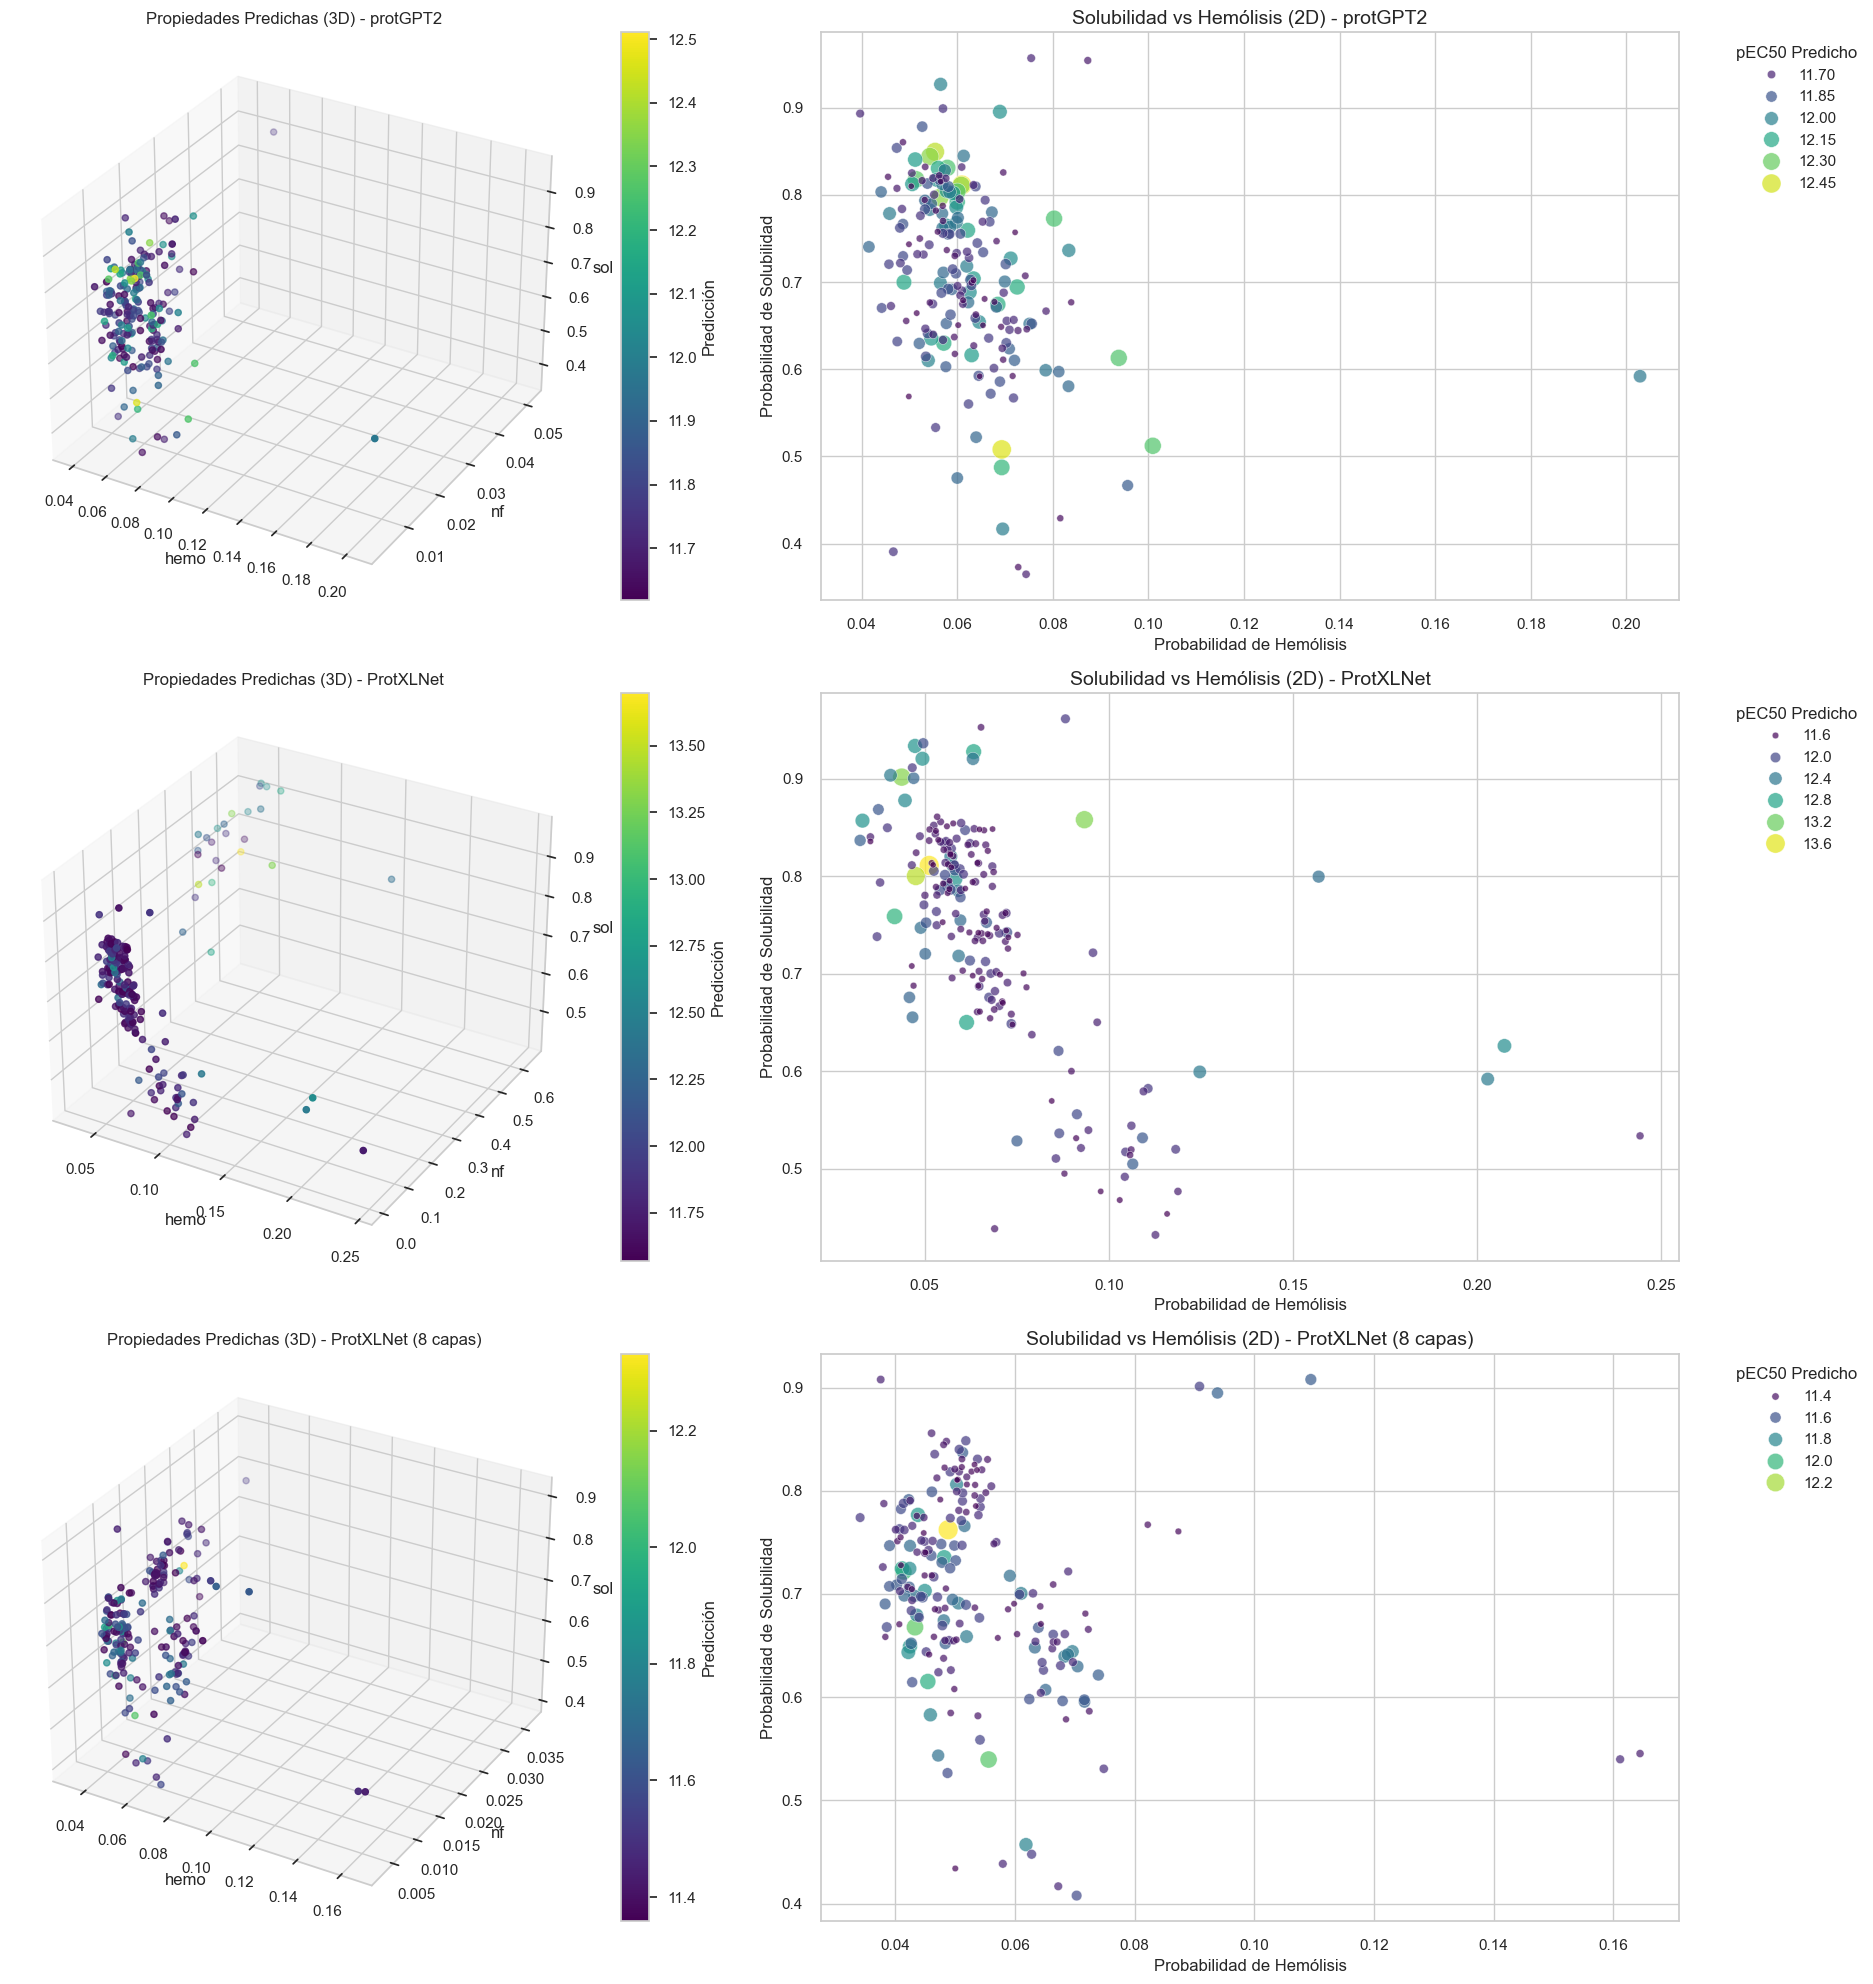

In [51]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Lista de dataframes y títulos para iterar (ajusta nombres)
datasets = [
    (df_secuencias_protGPT2, "protGPT2"),
    (df_secuencias_protxlnet, "ProtXLNet"),
    (df_secuencias_protxlnet_8, "ProtXLNet (8 capas)")
]

# Crear figura con 3 filas y 2 columnas

fig = plt.figure(figsize=(20, 20))  # Ajustar tamaño si hace falta

for i, (df, titulo) in enumerate(datasets, start=1):
    # Subplot 3D
    ax3d = fig.add_subplot(len(datasets), 2, (i - 1) * 2 + 1, projection='3d')
    plot_pca_3d(
        df.head(200),
        pc_x='hemo',
        pc_y='nf',
        pc_z='sol',
        color_by='prediccion_-1pEC50',
        label='Predicción',
        ax=ax3d,
        cmap='viridis',
        title=f'Propiedades Predichas (3D) - {titulo}',
    )

    # Subplot 2D
    ax2d = fig.add_subplot(len(datasets), 2, (i - 1) * 2 + 2)
    scatter = sns.scatterplot(
        data=df.head(200),
        x='hemo',
        y='sol',
        hue='prediccion_-1pEC50',
        palette='viridis',
        size='prediccion_-1pEC50',
        sizes=(20, 200),
        alpha=0.7,
        edgecolor='w',
        ax=ax2d
    )
    
    ax2d.set_title(f'Solubilidad vs Hemólisis (2D) - {titulo}', fontsize=14)
    ax2d.set_xlabel('Probabilidad de Hemólisis', fontsize=12)
    ax2d.set_ylabel('Probabilidad de Solubilidad', fontsize=12)
    ax2d.grid(True)
    ax2d.legend(title='pEC50 Predicho', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


# Conclusión

El presente trabajo logró su objetivo principal al implementar un pipeline de inteligencia artificial para la generación y evaluación *in silico* de nuevas secuencias peptídicas. A pesar de los desafíos metodológicos, se identificaron candidatos con una alta actividad agonista de GLP-1 predicha, algunos de los cuales mostraron un potencial teórico superior al péptido humano de referencia, lo que sugiere su viabilidad como base para el desarrollo de futuros fármacos.

Sin embargo, se observa que los modelos de lenguaje generativos utilizados (ProtXLNet y ProtGPT2) se encuentran aún en una etapa "experimental" para esta tarea específica. En particular, ProtXLNet demostró ser inmaduro, ya que tendió a repetir secuencias de aminoácidos, generando resultados con baja diversidad o incluso secuencias inválidas, a pesar del entrenamiento con un conjunto diverso de secuencias GLP-1. No obstante, generó secuencias con mejores características que ProtGPT2. Por otro lado, ProtGPT2 ofreció un desempeño relativamente superior al generar secuencias más variadas y estructuralmente válidas sin repeticiones excesivas, pero la eficacia biológica predicha fue en general, menor, posiblemente debido a su tendencia a generar secuencias completamente nuevas en lugar de modificar gradualmente una secuencia inicial, como lo hace ProtXLNet. ProtGPT2 produjo secuencias más realistas y cercanas a las biológicas conocidas, pero no necesariamente más efectivas.

A este respecto, ProtGPT2 generó secuencias con las siguientes características de actividad biológica pEC50:

| Potencia | n    | Promedio   | Min        | Max        |
|----------|------|------------|------------|------------|
| Alta     | 1737 | 10.838746  | 10.518702  | 11.840127  |
| Baja     | 1686 | 9.563515   | 6.107145   | 10.045160  |
| Media    | 1686 | 10.291403  | 10.045923  | 10.518688  |

Mientras que ProtXLNet obtuvo las siguientes características:

| Potencia | n    | Promedio   | Min        | Max        |
|----------|------|------------|------------|------------|
| Alta     | 540  | 11.204675  | 10.902108  | 12.031101  |
| Baja     | 525  | 9.691591   | 6.827128   | 10.279742  |
| Media    | 524  | 10.612945  | 10.280780  | 10.898850  |

Cabe destacar que ProtXLNet también presentó problemas de desempeño computacional: a pesar de ser un modelo más pequeño (30 capas frente a las 36 de ProtGPT2), requirió significativamente más tiempo para generar secuencias.

Ante las limitaciones observadas en cuanto a calidad, control y optimización de las secuencias generadas, se considera que la incorporación de algoritmos genéticos representa una alternativa metodológica más prometedora para trabajos futuros. Estos permitirían una exploración más dirigida, combinando secuencias con las mejores características para maximizar la actividad biológica, superando así la naturaleza menos controlada de los modelos de lenguaje. Otra línea viable sería la adopción de modelos de lenguaje más recientes, como aquellos basados en arquitecturas LLaMA o Gemma, aunque actualmente no existen referencias aplicadas al diseño de proteínas con dichos modelos.

El análisis de los resultados obtenidos mediante el modelo predictivo entrenado con péptidos de actividad biológica conocida también muestra la posibilidad de emplear secuencias derivadas de especies existentes para sintetizar compuestos viables, siguiendo un enfoque similar al utilizado en el desarrollo de la liraglutida, derivada del GLP-1 de otra especie.

A este respecto, el modelo predictivo obtuvo las siguientes métricas:

| Fold | MAE     | MSE     | RMSE    | R2      | RMSLE   | MAPE    |
|------|---------|---------|---------|---------|---------|---------|
| **Mean** | **0.6334** | **0.7794** | **0.8146** | **0.6437** | **0.0779** | **0.0689** |
| **Std**  | **0.2570** | **0.7524** | **0.3402** | **0.3101** | **0.0337** | **0.0319** |

Si bien el modelo presenta métricas razonables considerando la limitada cantidad de datos disponibles, se decidió no continuar con su entrenamiento debido a la escasez de información adicional para mejorar las predicciones y a señales visibles de sobreajuste. Este modelo consiste en un *blending* de tres algoritmos: **CatBoost Regressor**, **ExtraTreesRegressor** y **HuberRegressor**, y en general tiende a subestimar la actividad biológica, como se aprecia en los gráficos correspondientes a la distribución de los valores predichos de -1pEC50.

En general, este trabajo muestra que es posible establecer un pipeline basado en inteligencia artificial para la investigación de compuestos análogos al GLP-1 y, potencialmente, otros péptidos de interés, siempre que se cuente con datos suficientes que permitan entrenar modelos predictivos robustos.


## Referencias
* Elnaggar, A., Heinzinger, M., Dallago, C., Rehawi, G., Wang, Y., Jones, L., Gibbs, T., Feher, T., Angerer, C., Steinegger, M., Bhowmik, D., & Rost, B. (2021). ProtTrans: Toward Understanding the Language of Life Through Self-Supervised Learning. IEEE Transactions On Pattern Analysis And Machine Intelligence, 44(10), 7112-7127. https://doi.org/10.1109/tpami.2021.3095381

Ferruz, N., Schmidt, S., & Höcker, B. (2022). ProtGPT2 is a deep unsupervised language model for protein design. Nature Communications, 13(1). https://doi.org/10.1038/s41467-022-32007-7

* Grasso, G., Musso, N., & Rizzarelli, E. (2021). Toxicological assessment of peptide-based therapeutics: The role of hemolysis studies. Toxins, 13(4), 278. https://doi.org/10.3390/toxins13040278


* White, A. D., Nowinski, A. K., & Keefe, A. J. (2019). Non-fouling surfaces: Design and applications. Annual Review of Chemical and Biomolecular Engineering, 10, 17–39. https://doi.org/10.1146/annurev-chembioeng-060718-030022

* Zhou, X., Chen, Y., & Liu, Y. (2023). AI-driven drug discovery: Integrating computational models with biological data. Nature Reviews Drug Discovery, 22(4), 271–289. https://doi.org/10.1038/s41573-023-00231-7

* Puszkarska, A. M., Taddese, B., Revell, J., Davies, G., Field, J., Hornigold, D. C., Buchanan, A., Vaughan, T. J., & Colwell, L. J. (2024). Machine learning designs new GCGR/GLP-1R dual agonists with enhanced biological potency. Nature Chemistry, 16(9), 1436-1444. https://doi.org/10.1038/s41557-024-01532-x

* Chou, K. (2001). Prediction of protein cellular attributes using pseudo‐amino acid composition. Proteins Structure Function And Bioinformatics, 43(3), 246-255. https://doi.org/10.1002/prot.1035

* Guntuboina, C., Das, A., Mollaei, P., Kim, S., & Farimani, A. B. (2023). PeptideBERT: A Language Model Based on Transformers for Peptide Property Prediction. The Journal Of Physical Chemistry Letters, 14(46), 10427-10434. https://doi.org/10.1021/acs.jpclett.3c02398